# Notebook 11 — `11_xgboost_shap_sectors`

## Overview

**Purpose:** Run the full XGBoost + SHAP predictive pipeline across all 17 GRDP
sectors, and compare each sector's predictive result against the fixed-effects
flood-block result read from `fit_9b.json`. This is the sector-level predictive
companion to the inferential 9b/9d results; it shows that even sectors with a
significant FE flood block have little out-of-sample predictive skill.

## Data requirements

This notebook runs on the model-ready panel exported by Notebook 8; no raw data
download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Model-ready panel (`transformed` sheet) | Notebook 8 | `data/processed/8_panel_data.xlsx` |

Additionally reads `fit_9b.json` (the 3-dimension sector FE results from Notebook 9b).

## Workflow

| Step | Description |
|---|---|
| 1 | Setup, parameter grid, and the per-sector pipeline function |
| 2 | Run the pipeline across the 17 sectors (per `SECTORS_TO_RUN`) |
| 3 | FE vs XGBoost comparison (FE read from `fit_9b.json`) |

## Outputs

| File | Description |
|---|---|
| (in-notebook) | Per-sector CV-R² and flood SHAP-share, with the FE-vs-XGBoost comparison table |

---
## STEP 1 — Setup and per-sector pipeline

Import libraries, define the full parameter grid (identical to the headline growth run), and define `run_full_sector`, the function that executes the whole XGBoost + SHAP pipeline for one sector outcome.

In [1]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Setup & per-sector pipeline
# ═════════════════════════════════════════════════════════════
import pandas as pd, numpy as np, warnings, json
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import xgboost as xgb, shap
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_score, learning_curve
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.base import clone

panel = pd.read_excel("../data/processed/8_panel_data.xlsx", "transformed").sort_values(["bps_kab_code", "year"])
FLOOD    = ["event_count_log", "HCI_log", "PDI_log"]
CONTROLS = ["log_population", "rls_years"]
FEATURES = FLOOD + CONTROLS
SECTORS  = [c for c in panel.columns
            if c.startswith("grdp_") and c.endswith("growth") and c != "grdp_growth_pct"]

# ── SWITCH: test one sector first, then set to SECTORS for all 17 ──
#SECTORS_TO_RUN = ["grdp_G_trade_growth"]     # ← change to SECTORS for the full run
SECTORS_TO_RUN = SECTORS

print(f"Will run: {[s.replace('grdp_','').replace('_growth','') for s in SECTORS_TO_RUN]}")

Will run: ['A_agriculture', 'B_mining', 'C_manufacturing', 'D_electricity', 'E_water', 'F_construction', 'G_trade', 'H_transport', 'I_accommodation', 'J_infocomm', 'K_finance', 'L_realestate', 'MN_business', 'O_government', 'P_education', 'Q_health', 'RSTU_other']


In [3]:
# Full nb11 parameter grid (324 combinations) — identical to headline growth
PARAM_GRID = {
    "n_estimators":     [100, 300, 500],
    "max_depth":        [2, 3, 4],
    "learning_rate":    [0.01, 0.05, 0.1],
    "subsample":        [0.8],
    "colsample_bytree": [0.8],
    "min_child_weight": [5, 10],
    "reg_alpha":        [0, 0.1, 1.0],
    "reg_lambda":       [1.0, 5.0],
}

def cv_metrics(est, X, y, groups, cv):
    r2s, rmses, maes = [], [], []
    for tr_i, te_i in cv.split(X, y, groups):
        m = clone(est); m.fit(X[tr_i], y[tr_i]); p = m.predict(X[te_i])
        r2s.append(r2_score(y[te_i], p)); rmses.append(np.sqrt(mean_squared_error(y[te_i], p)))
        maes.append(mean_absolute_error(y[te_i], p))
    return np.mean(r2s), np.std(r2s), np.mean(rmses), np.mean(maes)

print("Grid ready:", int(np.prod([len(v) for v in PARAM_GRID.values()])), "combinations")

Grid ready: 324 combinations


In [4]:
def run_full_sector(outcome):
    """Full nb11 pipeline for one outcome. Prints tables, draws all plots,
    returns a summary dict for the final FE-vs-XGBoost comparison."""
    name = outcome.replace("grdp_", "").replace("_growth", "")
    print("\n" + "#"*70)
    print(f"#  SECTOR: {name}")
    print("#"*70)

    d = panel.dropna(subset=[outcome] + FEATURES).copy()
    tr = d[d.year <= 2022]; va = d[d.year == 2023]; te = d[d.year >= 2024]
    X_tr, y_tr, g_tr = tr[FEATURES].values, tr[outcome].values, tr["bps_kab_code"].values
    X_va, y_va = va[FEATURES].values, va[outcome].values
    X_te, y_te = te[FEATURES].values, te[outcome].values
    gkf = GroupKFold(5)

    # ---- 1. TUNING ----
    gs = GridSearchCV(xgb.XGBRegressor(random_state=42, objective="reg:squarederror"),
                      PARAM_GRID, cv=gkf.split(X_tr, y_tr, g_tr),
                      scoring="r2", n_jobs=-1)
    gs.fit(X_tr, y_tr); best = gs.best_estimator_
    print(f"\nBest params: {gs.best_params_}")
    print(f"Best grouped-CV R2 (train): {gs.best_score_:+.4f}")

    # ---- 2. THREE-STAGE EVAL ----
    cv_r2, cv_sd, cv_rmse, cv_mae = cv_metrics(best, X_tr, y_tr, g_tr, gkf)
    def stg(yt, yp): return r2_score(yt, yp), np.sqrt(mean_squared_error(yt, yp)), mean_absolute_error(yt, yp)
    r2_va, rmse_va, mae_va = stg(y_va, best.predict(X_va))
    r2_te, rmse_te, mae_te = stg(y_te, best.predict(X_te))
    naive = np.full(len(y_te), y_tr.mean()); r2_n, rmse_n, mae_n = stg(y_te, naive)
    print("\nPERFORMANCE ACROSS THE THREE STAGES")
    print(f"  {'Stage':<22}{'R2':>9}{'RMSE':>9}{'MAE':>9}")
    print(f"  {'Train (CV)':<22}{cv_r2:>+9.4f}{cv_rmse:>9.3f}{cv_mae:>9.3f}")
    print(f"  {'Validation (2023)':<22}{r2_va:>+9.4f}{rmse_va:>9.3f}{mae_va:>9.3f}")
    print(f"  {'Test (2024-25)':<22}{r2_te:>+9.4f}{rmse_te:>9.3f}{mae_te:>9.3f}")
    print(f"  {'Naive baseline':<22}{r2_n:>+9.4f}{rmse_n:>9.3f}{mae_n:>9.3f}")

    # ---- 3. VALIDATION CURVE (L1/L2) ----
    _base = dict(best.get_params()); [_base.pop(k, None) for k in ("reg_alpha","reg_lambda")]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    for ax, param, grid, fixed in [(axes[0],"reg_alpha",[0,0.1,0.5,1,2,5],{"reg_lambda":1.0}),
                                    (axes[1],"reg_lambda",[0,0.5,1,2,5,10],{"reg_alpha":0.1})]:
        vals=[]
        for gv in grid:
            kw=dict(_base); kw.update(fixed); kw[param]=gv
            m=xgb.XGBRegressor(**kw)
            vals.append(cross_val_score(m,X_tr,y_tr,cv=gkf.split(X_tr,y_tr,g_tr),scoring="r2").mean())
        ax.plot(range(len(grid)), vals, "o-", color="#1C7293")
        ax.axhline(0, color="#999", ls="--", lw=1)
        ax.set_xticks(range(len(grid))); ax.set_xticklabels(grid)
        ax.set_title(f"{name} — {param}"); ax.set_xlabel(param); ax.set_ylabel("CV-R2")
    plt.tight_layout(); plt.show()

    # ---- 4. LEARNING CURVE ----
    _d = d.dropna(subset=[outcome]+FEATURES)
    _X,_y,_g = _d[FEATURES].values,_d[outcome].values,_d["bps_kab_code"].values
    sizes, trs, cvs = learning_curve(clone(best), _X, _y, groups=_g,
                                     cv=gkf, train_sizes=np.linspace(0.2,1.0,5), scoring="r2")
    plt.figure(figsize=(7,3.4))
    plt.plot(sizes, trs.mean(1), "o-", color="#c0392b", label="train R2")
    plt.plot(sizes, cvs.mean(1), "s-", color="#1f6f54", label="CV R2")
    plt.axhline(0,color="#999",ls="--",lw=1); plt.legend()
    plt.title(f"{name} — learning curve"); plt.xlabel("n_train"); plt.ylabel("R2"); plt.show()

    # ---- 5. DEPTH SWEEP (under/over-fit) ----
    depths=[1,2,3,4,6,10]; d_tr=[]; d_cv=[]
    for dp in depths:
        kw=dict(_base); kw["max_depth"]=dp
        m=xgb.XGBRegressor(**kw); m.fit(X_tr,y_tr)
        d_tr.append(r2_score(y_tr,m.predict(X_tr)))
        d_cv.append(cross_val_score(m,X_tr,y_tr,cv=gkf.split(X_tr,y_tr,g_tr),scoring="r2").mean())
    plt.figure(figsize=(7,3.4))
    xp=range(len(depths))
    plt.plot(xp,d_tr,"o-",color="#c0392b",label="train R2")
    plt.plot(xp,d_cv,"s-",color="#1f6f54",label="CV R2")
    plt.fill_between(xp,d_cv,d_tr,alpha=0.1,color="#888",label="gap=overfit")
    plt.axhline(0,color="#999",ls="--",lw=1); plt.xticks(list(xp),depths); plt.legend()
    plt.title(f"{name} — under/over-fitting"); plt.xlabel("max_depth"); plt.ylabel("R2"); plt.show()

    # ---- 6. BOOTSTRAP ----
    _Xr,_yr = pd.DataFrame(_X,columns=FEATURES).reset_index(drop=True), pd.Series(_y)
    np.random.seed(42); n=len(_Xr); r2s=[]; imps=[]
    for _b in range(200):
        idx=np.random.choice(n,n,replace=True); oob=np.setdiff1d(np.arange(n),idx)
        if len(oob)<50: continue
        m=xgb.XGBRegressor(**dict(best.get_params())); m.fit(_Xr.iloc[idx],_yr.iloc[idx])
        r2s.append(r2_score(_yr.iloc[oob],m.predict(_Xr.iloc[oob])))
        imps.append(np.abs(shap.TreeExplainer(m).shap_values(_Xr.iloc[oob][:100])).mean(0))
    r2s=np.array(r2s); imps=np.array(imps)
    ci=(np.percentile(r2s,2.5),np.percentile(r2s,97.5))
    fig,(b1,b2)=plt.subplots(1,2,figsize=(11,3.2))
    b1.hist(r2s,bins=30,color="#1f6f54",alpha=0.75); b1.axvline(0,color="#c0392b",ls="--")
    b1.set_title(f"{name} — bootstrap R2  95%CI=[{ci[0]:+.3f},{ci[1]:+.3f}]"); b1.set_xlabel("OOB R2")
    means=imps.mean(0); order=np.argsort(means)
    b2.barh([FEATURES[i] for i in order],means[order],
            xerr=[(means-np.percentile(imps,2.5,0))[order],(np.percentile(imps,97.5,0)-means)[order]],
            color="#854f0b",alpha=0.75)
    b2.set_title("SHAP importance (95% CI)"); b2.set_xlabel("mean |SHAP|")
    plt.tight_layout(); plt.show()

    # ---- 7. SHAP: base value + waterfall + beeswarm + bar ----
    expl=shap.TreeExplainer(best); sv=expl.shap_values(X_te); base=expl.expected_value
    imp=np.abs(sv).mean(0); flood_share=imp[:3].sum()/imp.sum()*100
    print(f"\nSHAP base value = {base:.3f} (≈ mean {y_tr.mean():.3f})")
    print(f"flood share = {flood_share:.0f}%  |  top = {FEATURES[int(np.argmax(imp))]}")
    eo=shap.Explanation(values=sv[0],base_values=base,data=X_te[0],feature_names=FEATURES)
    shap.plots.waterfall(eo, show=True)
    shap.summary_plot(sv, pd.DataFrame(X_te,columns=FEATURES), show=True)
    shap.summary_plot(sv, pd.DataFrame(X_te,columns=FEATURES), plot_type="bar", show=True)

    # ---- 8. PRED VS ACTUAL ----
    pred=best.predict(X_te)
    plt.figure(figsize=(5,4.2))
    plt.scatter(y_te,pred,s=10,alpha=0.4,color="#1C7293")
    lims=[min(y_te.min(),pred.min()),max(y_te.max(),pred.max())]
    plt.plot(lims,lims,"--",color="#999"); plt.xlabel("actual"); plt.ylabel("predicted")
    plt.title(f"{name} — pred vs actual (corr={np.corrcoef(y_te,pred)[0,1]:.2f})"); plt.show()
    print(f"std actual={y_te.std():.2f}  std pred={pred.std():.2f} ({pred.std()/y_te.std()*100:.0f}%)")

    return dict(sector=name, best_cv_r2=gs.best_score_, cv_r2=cv_r2,
                cv_rmse=cv_rmse, cv_mae=cv_mae,
                test_r2=r2_te, test_rmse=rmse_te, test_mae=mae_te,
                naive_r2=r2_n,
                flood_share=flood_share,
                top_feature=FEATURES[int(np.argmax(imp))],
                shap_event=imp[0], shap_hci=imp[1], shap_pdi=imp[2],
                shap_pop=imp[3], shap_rls=imp[4],
                boot_ci_low=ci[0], boot_ci_high=ci[1])

print("run_full_sector() ready.")

run_full_sector() ready.


## STEP 2 — Run the pipeline (per `SECTORS_TO_RUN`)


######################################################################
#  SECTOR: A_agriculture
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0634

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0623    2.376    1.868
  Validation (2023)       +0.0578    2.345    1.741
  Test (2024-25)          -0.0791    2.910    2.218
  Naive baseline          -0.0433    2.861    2.201


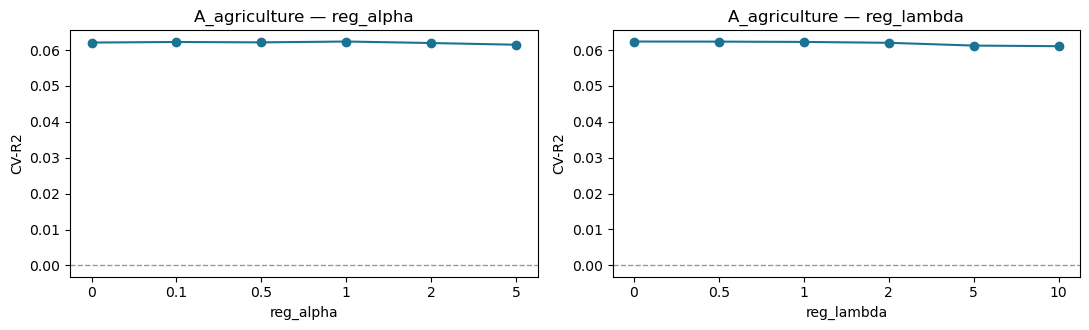

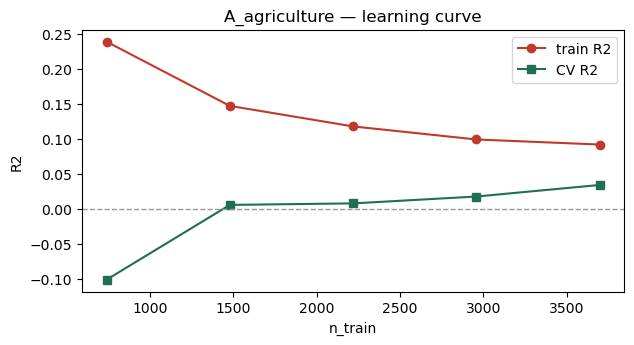

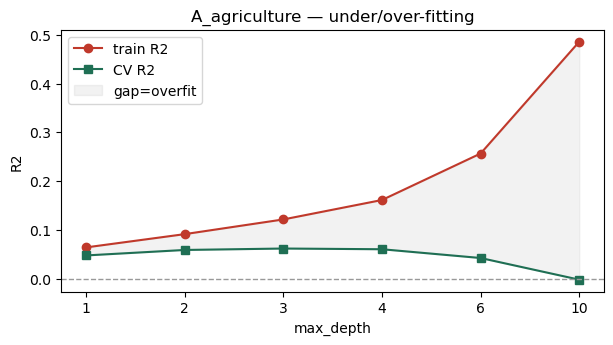

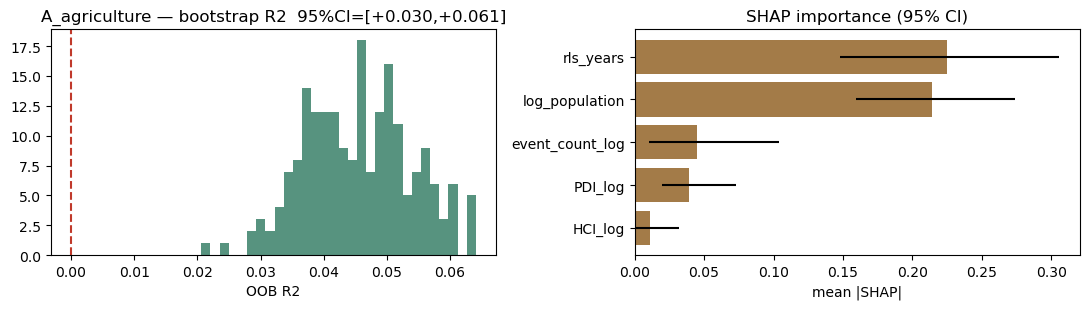


SHAP base value = 2.662 (≈ mean 2.661)
flood share = 28%  |  top = log_population


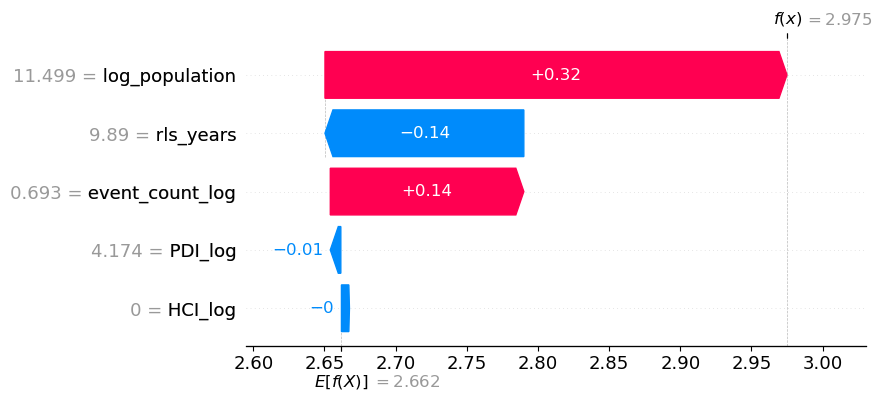

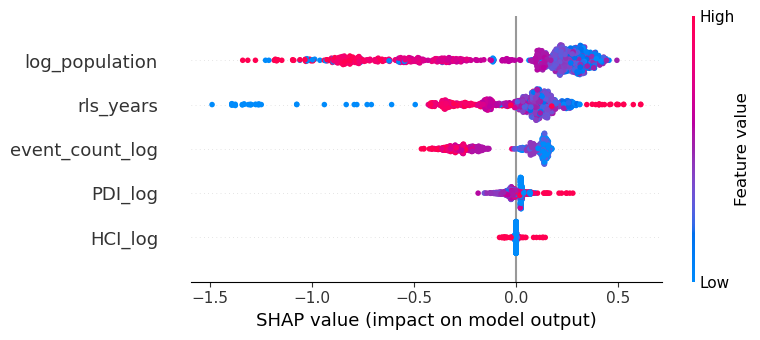

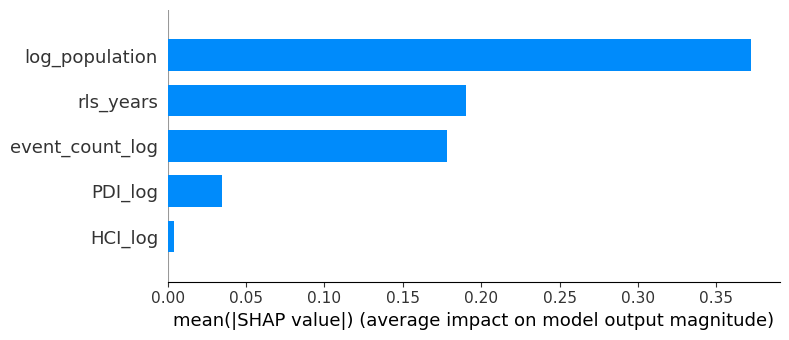

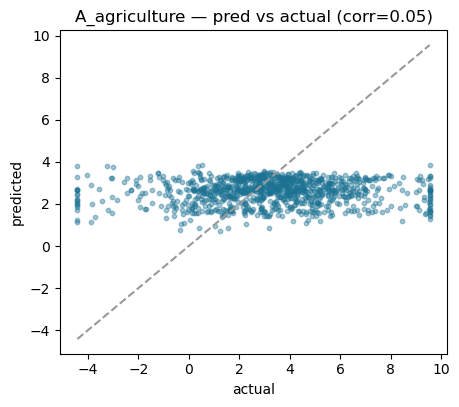

std actual=2.80  std pred=0.59 (21%)

######################################################################
#  SECTOR: B_mining
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 10, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0217

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0208    6.164    4.169
  Validation (2023)       +0.0214    5.570    3.439
  Test (2024-25)          +0.0226    5.815    3.711
  Naive baseline          -0.0002    5.882    3.725


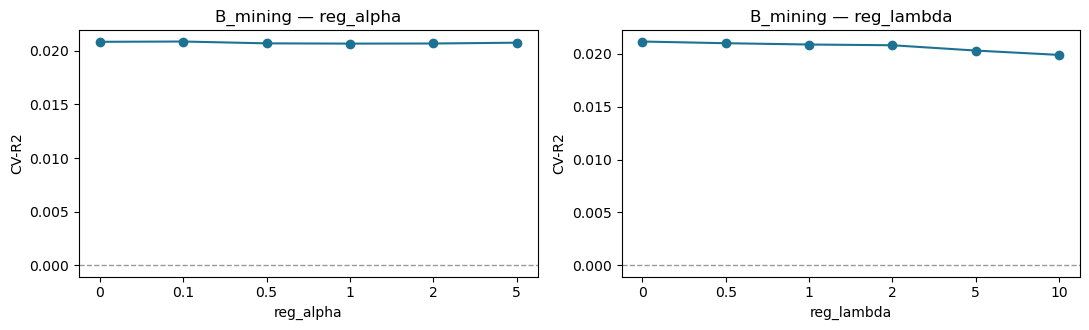

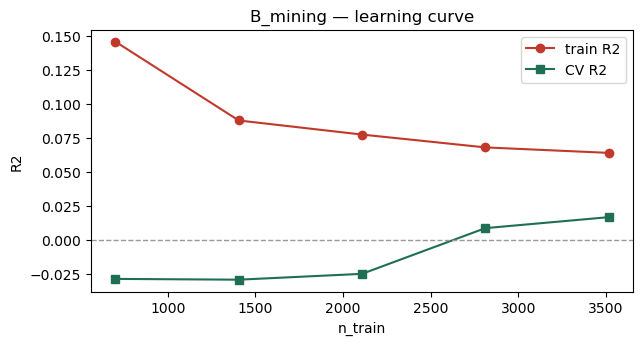

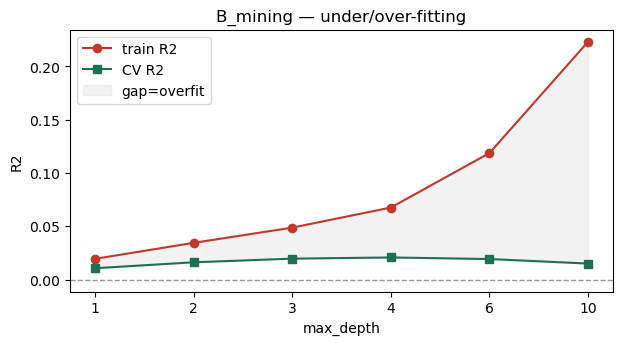

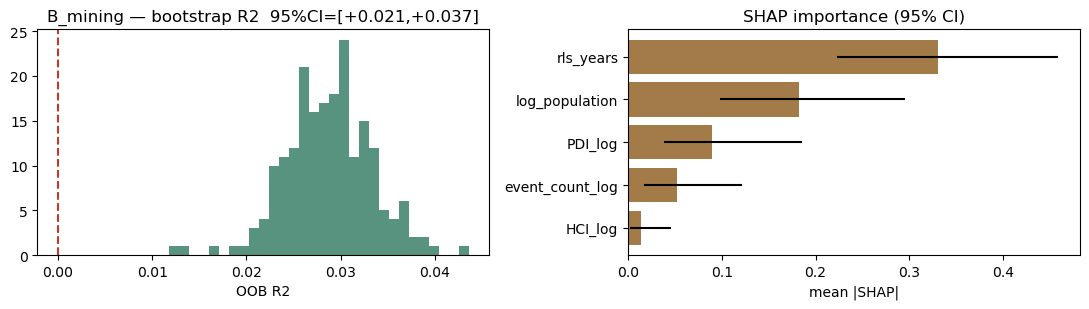


SHAP base value = 2.569 (≈ mean 2.558)
flood share = 23%  |  top = log_population


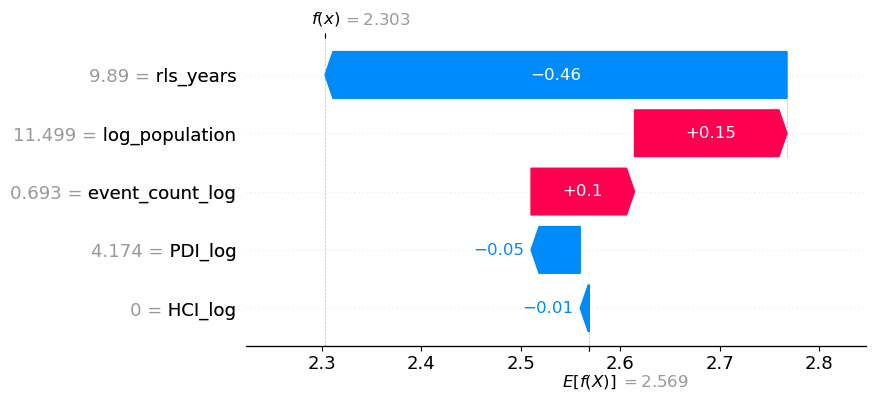

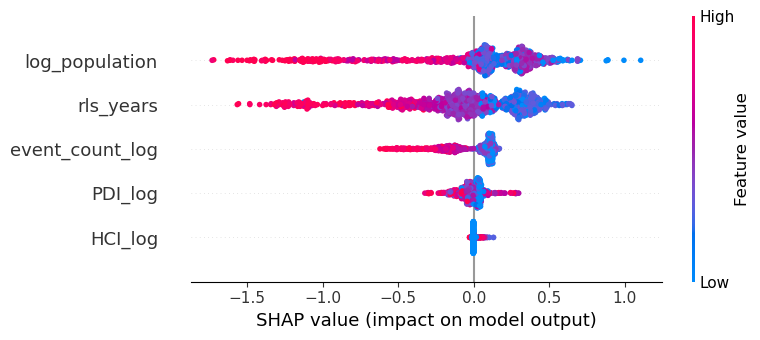

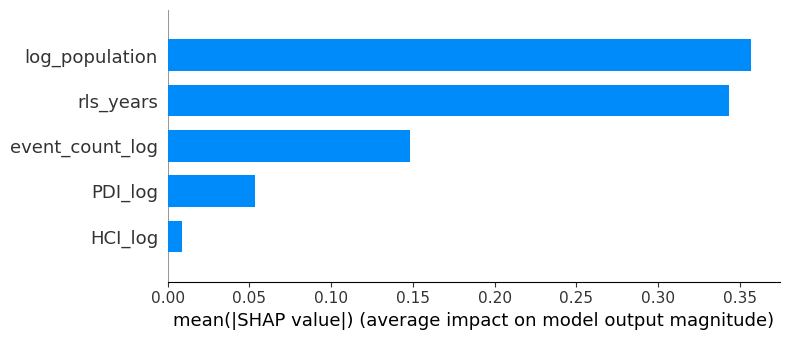

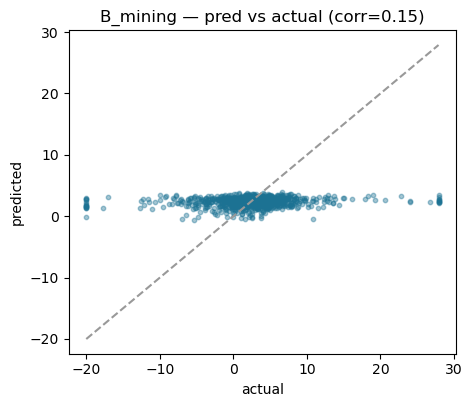

std actual=5.88  std pred=0.74 (12%)

######################################################################
#  SECTOR: C_manufacturing
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 300, 'reg_alpha': 0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0165

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0163    4.784    3.235
  Validation (2023)       +0.0196    4.667    2.841
  Test (2024-25)          -0.1381    5.326    3.310
  Naive baseline          -0.1266    5.299    3.298


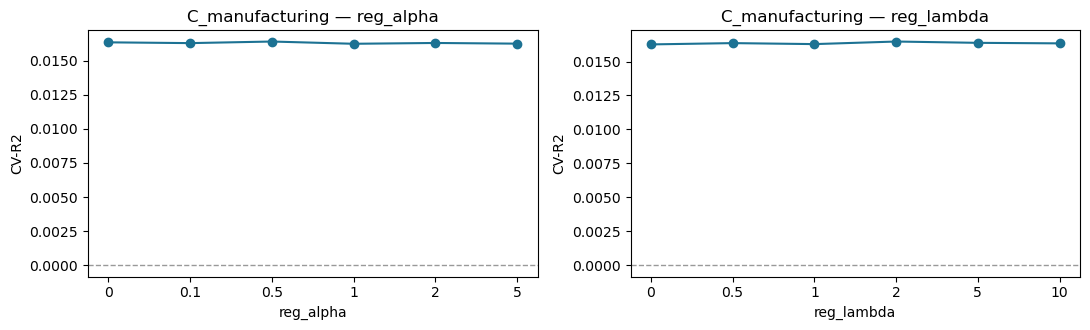

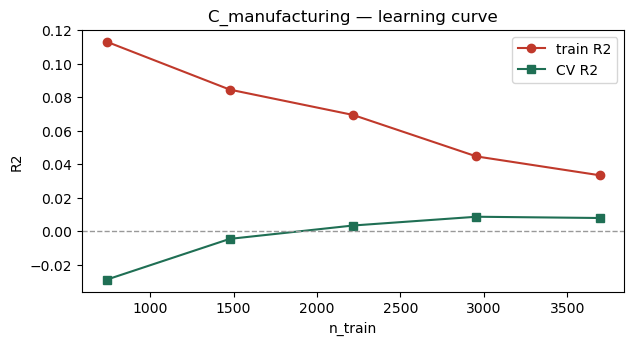

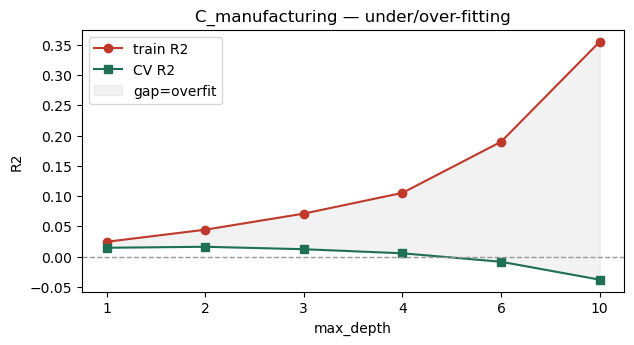

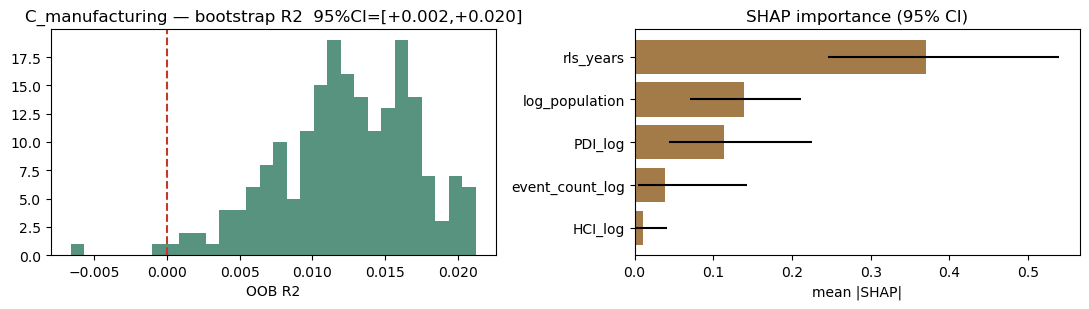


SHAP base value = 3.780 (≈ mean 3.773)
flood share = 33%  |  top = rls_years


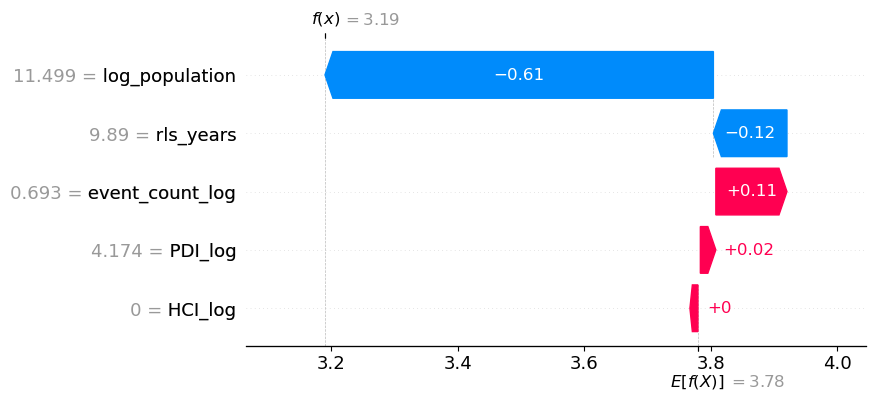

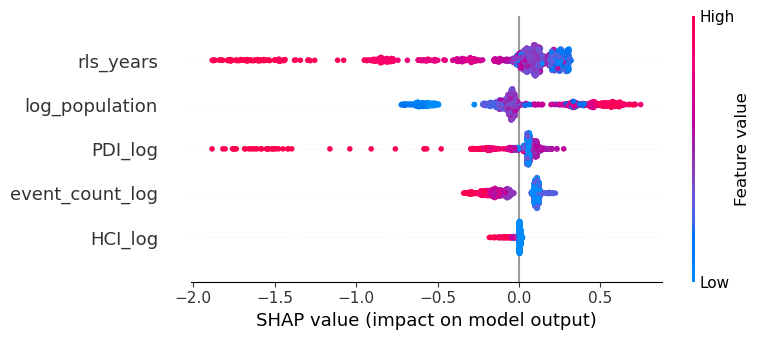

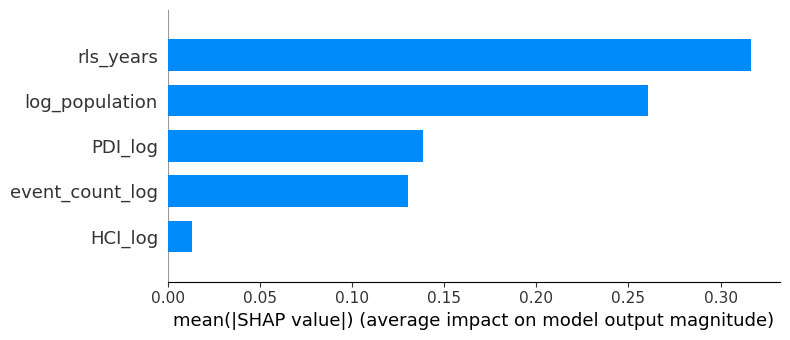

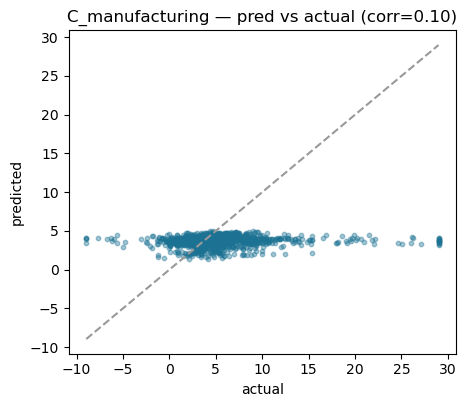

std actual=4.99  std pred=0.68 (14%)

######################################################################
#  SECTOR: D_electricity
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0364

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0366    4.483    3.094
  Validation (2023)       -0.0423    4.814    3.247
  Test (2024-25)          +0.0306    4.705    3.232
  Naive baseline          -0.0111    4.806    3.278


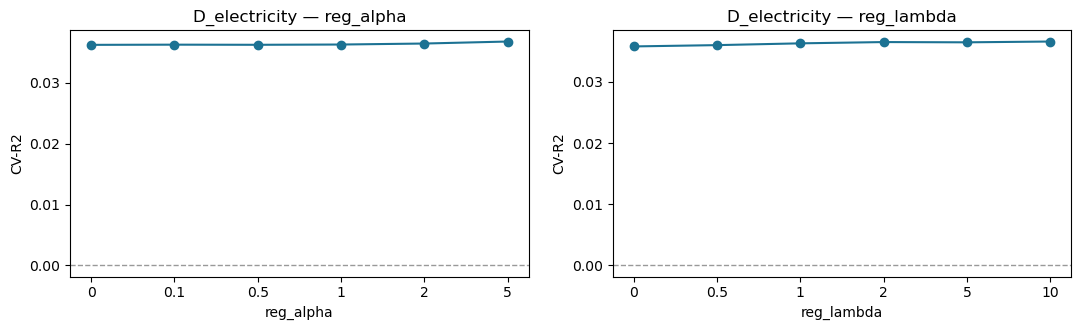

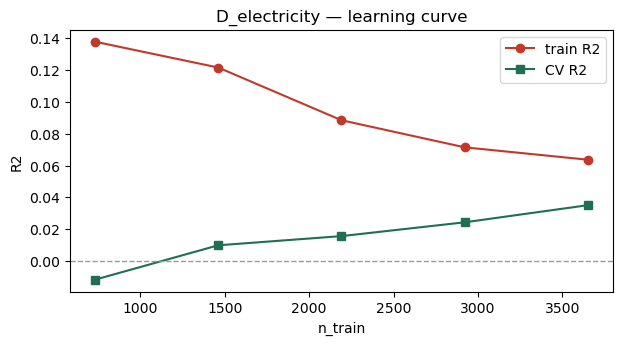

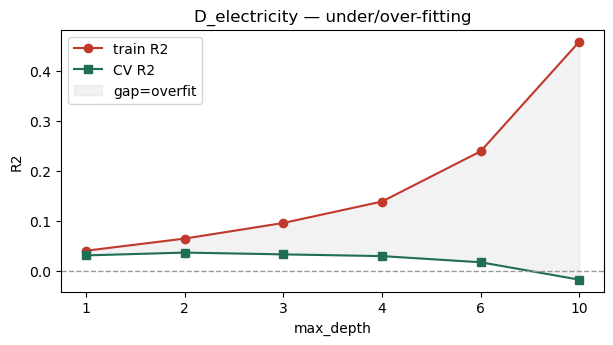

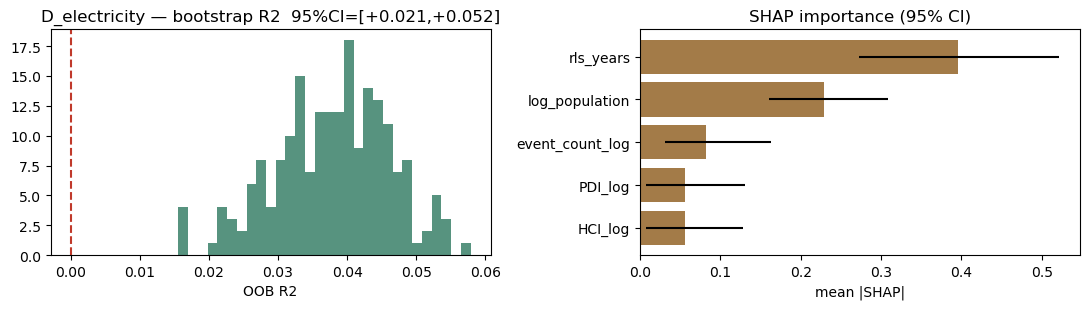


SHAP base value = 5.333 (≈ mean 5.331)
flood share = 22%  |  top = log_population


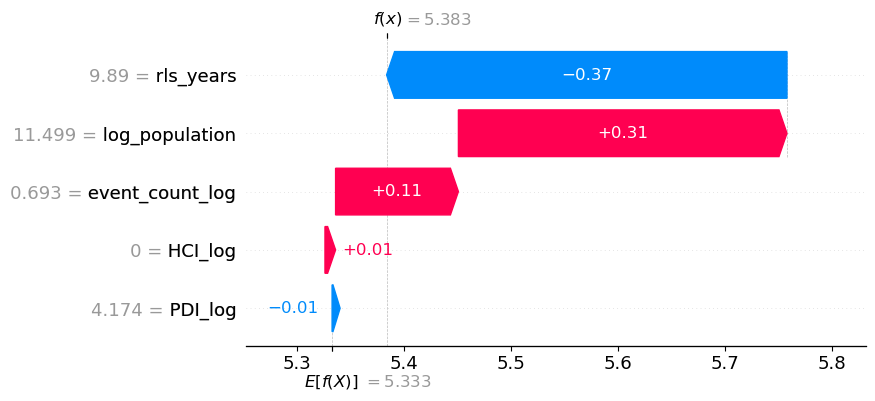

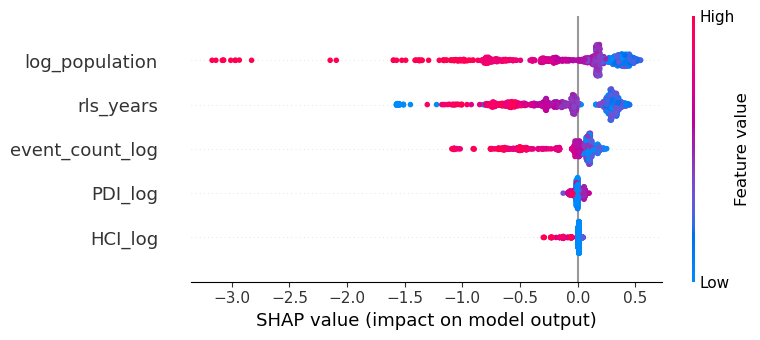

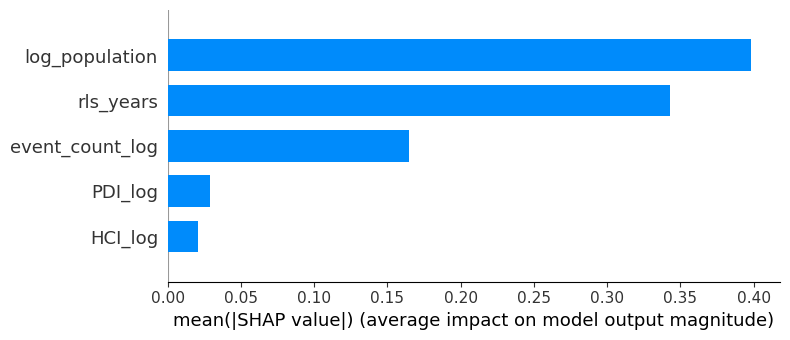

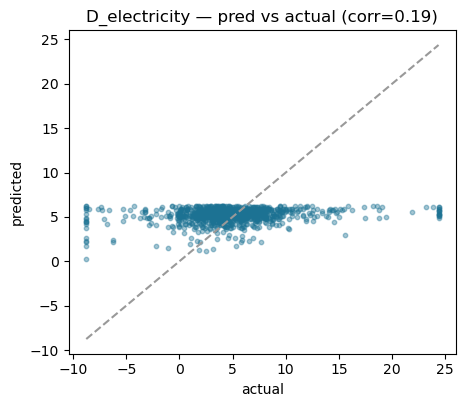

std actual=4.78  std pred=0.81 (17%)

######################################################################
#  SECTOR: E_water
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0187

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0186    3.270    2.487
  Validation (2023)       -0.0474    2.980    2.240
  Test (2024-25)          -0.1573    3.598    2.844
  Naive baseline          -0.1558    3.596    2.831


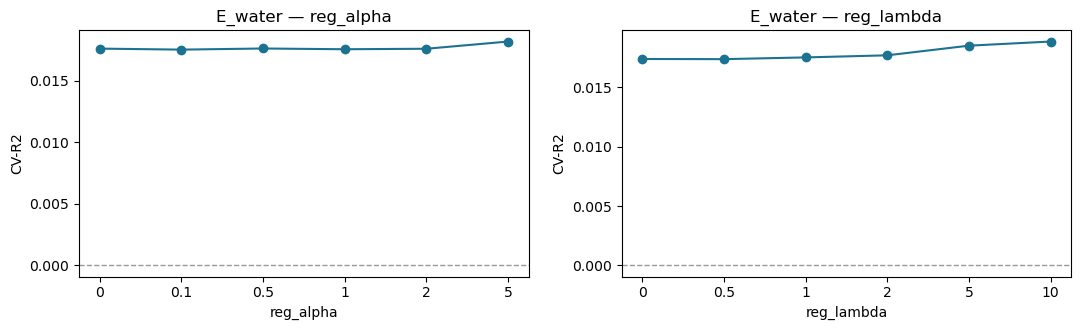

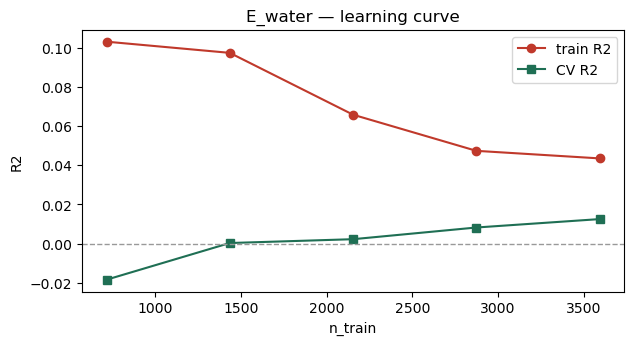

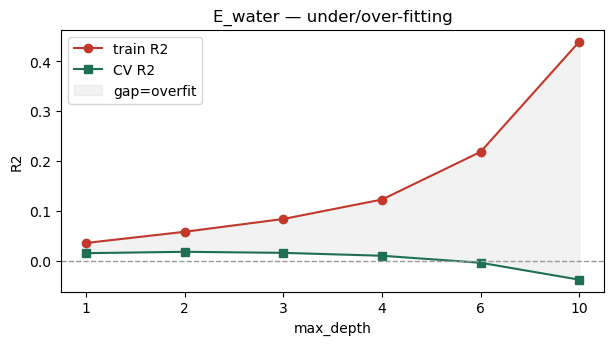

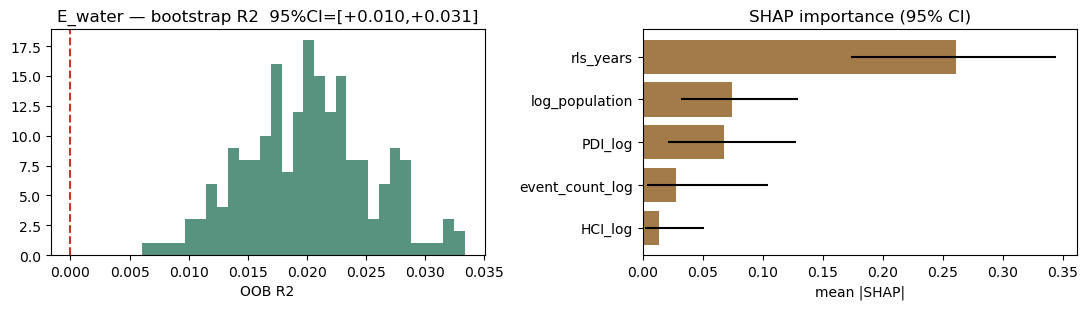


SHAP base value = 4.246 (≈ mean 4.250)
flood share = 13%  |  top = rls_years


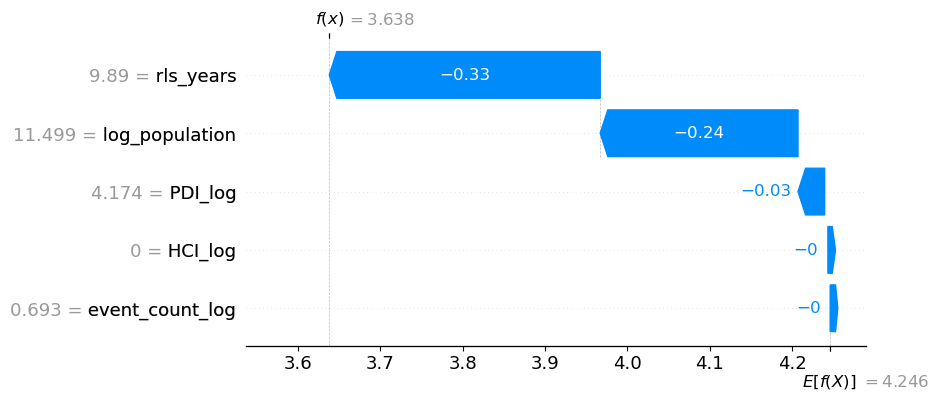

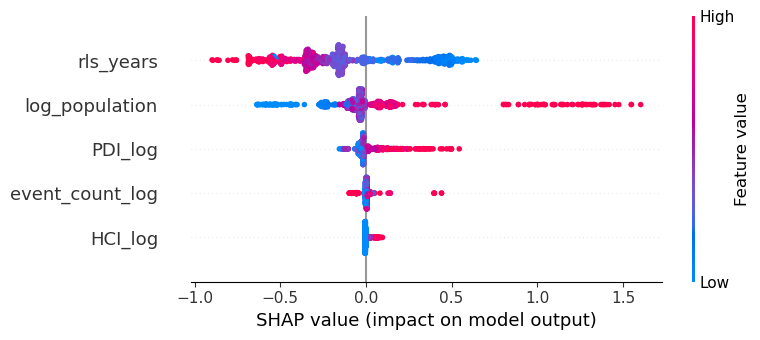

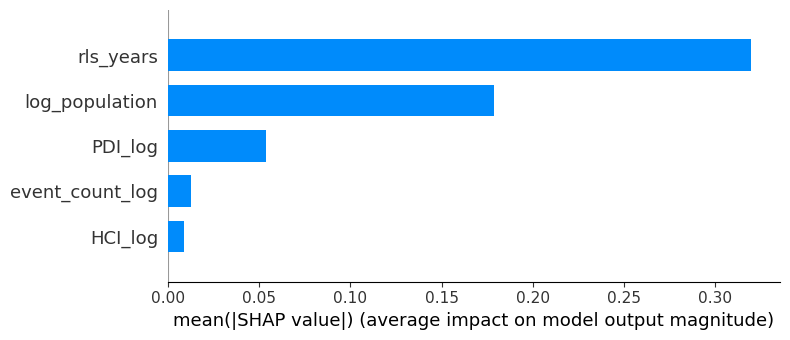

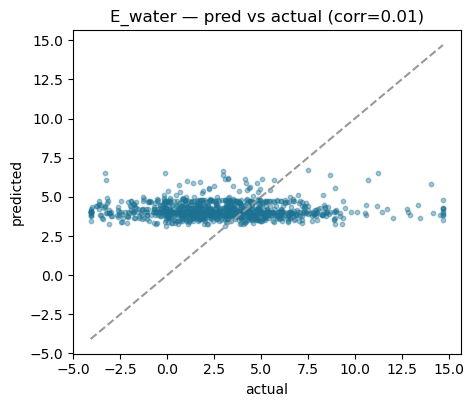

std actual=3.34  std pred=0.52 (16%)

######################################################################
#  SECTOR: F_construction
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 300, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0168

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0167    4.918    3.752
  Validation (2023)       -0.1359    4.187    3.023
  Test (2024-25)          -0.0133    4.257    3.152
  Naive baseline          -0.0077    4.246    3.111


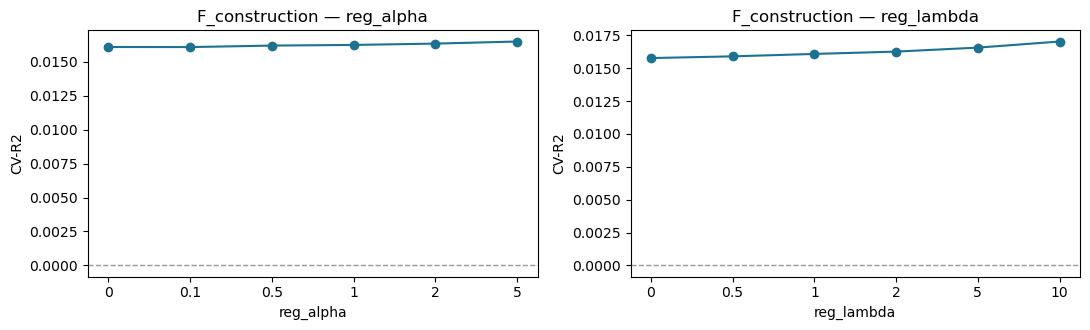

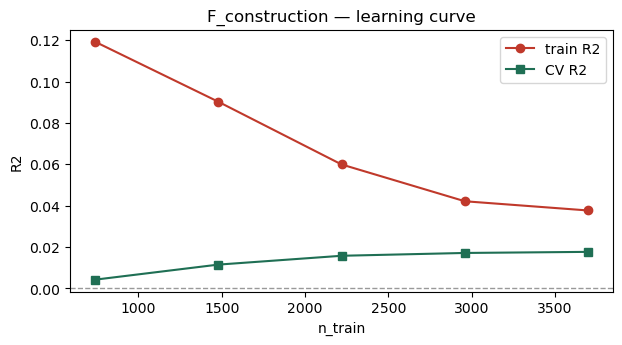

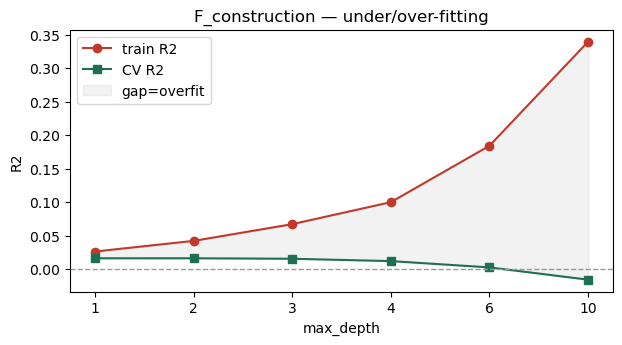

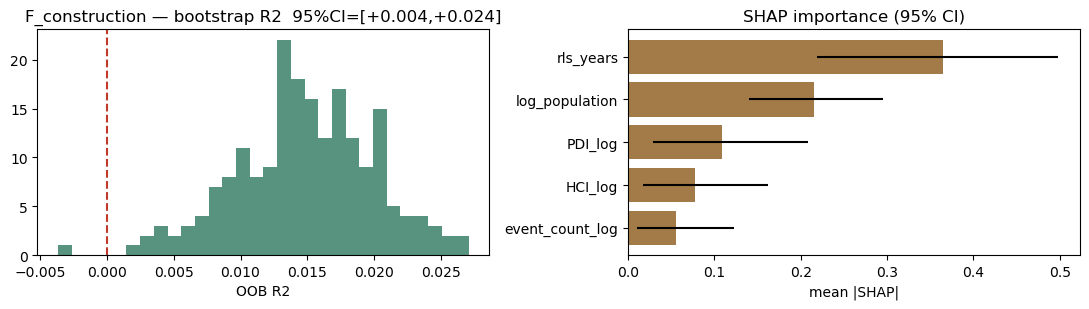


SHAP base value = 4.188 (≈ mean 4.185)
flood share = 41%  |  top = rls_years


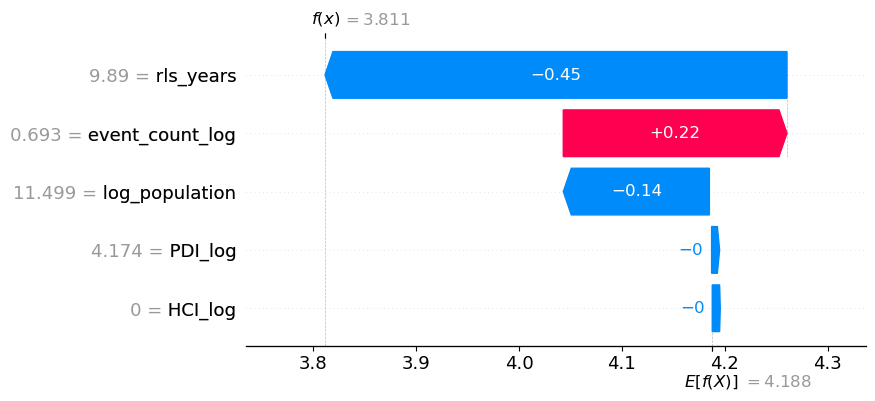

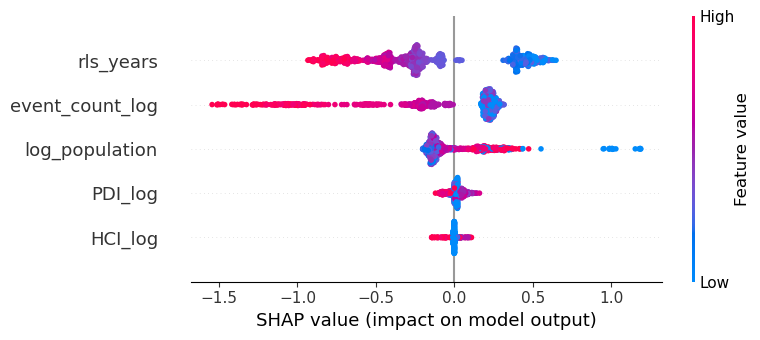

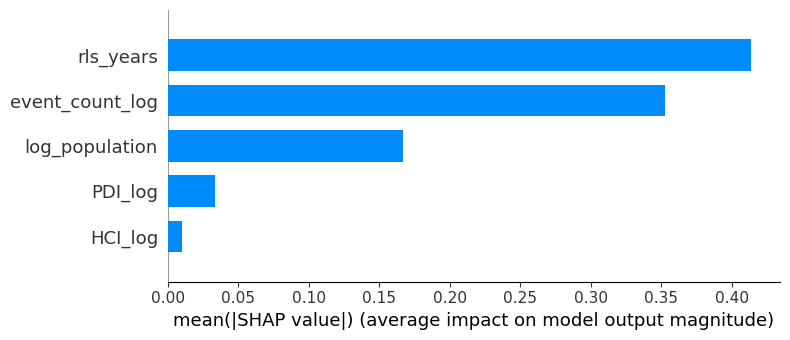

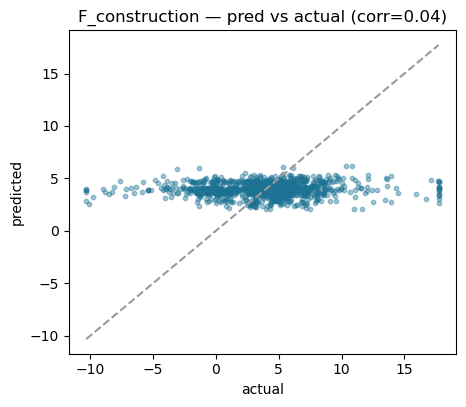

std actual=4.23  std pred=0.68 (16%)

######################################################################
#  SECTOR: G_trade
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 300, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0151

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0150    4.270    3.141
  Validation (2023)       -0.4392    2.847    2.159
  Test (2024-25)          -0.3090    2.965    2.199
  Naive baseline          -0.2442    2.891    2.086


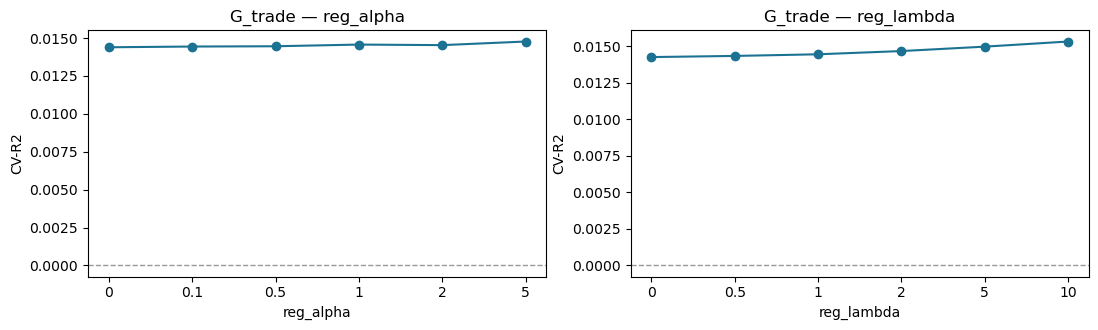

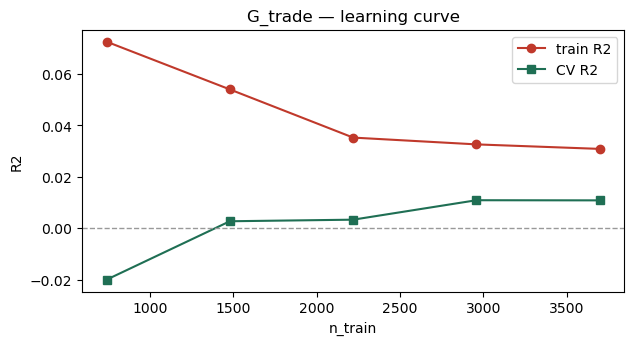

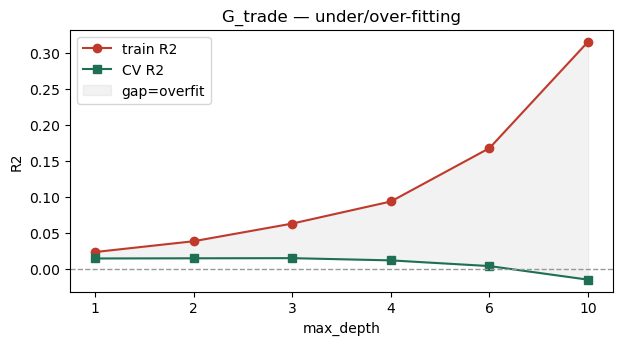

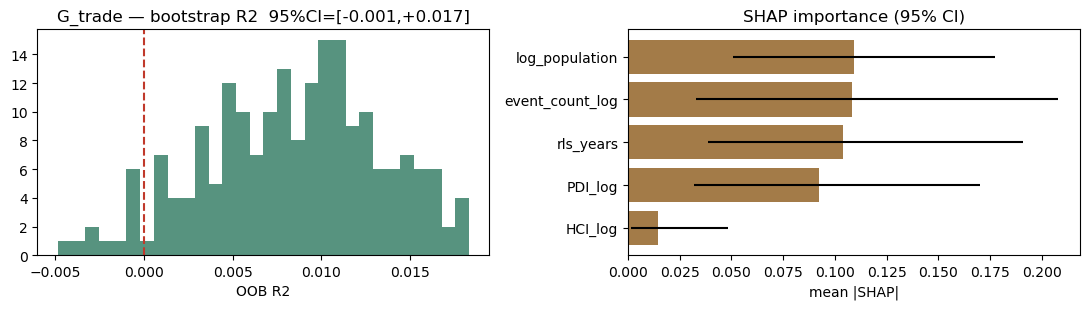


SHAP base value = 4.564 (≈ mean 4.558)
flood share = 55%  |  top = event_count_log


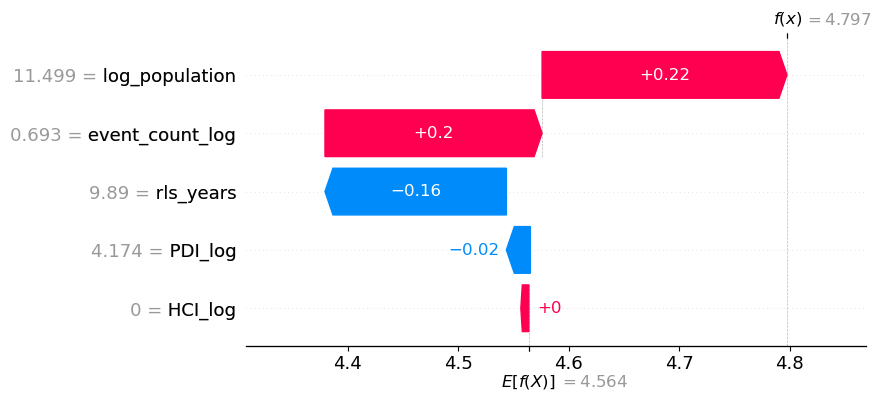

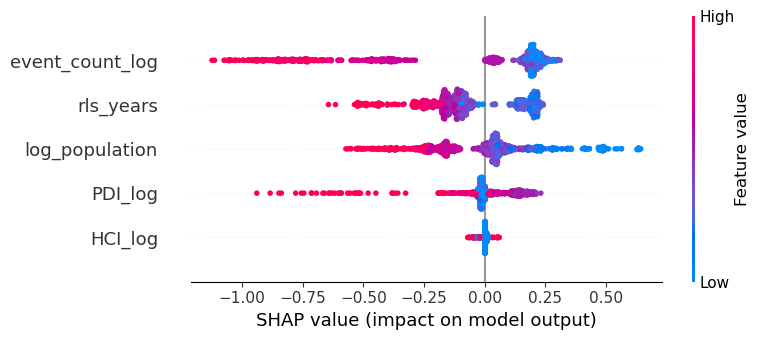

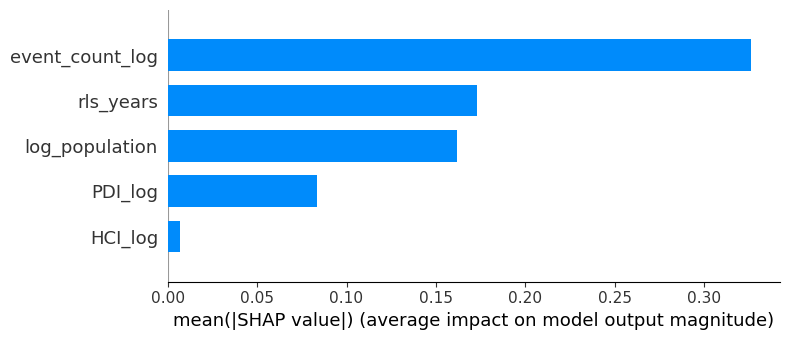

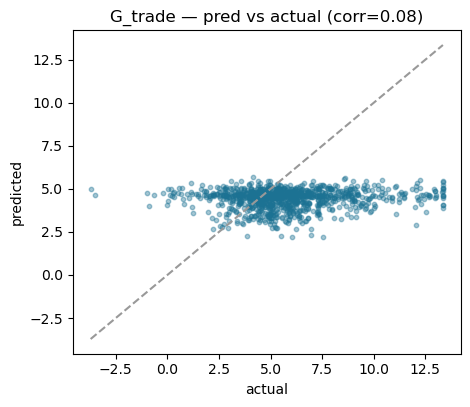

std actual=2.59  std pred=0.57 (22%)

######################################################################
#  SECTOR: H_transport
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 100, 'reg_alpha': 0.1, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0057

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0055    9.874    6.025
  Validation (2023)       -0.5738    5.883    4.218
  Test (2024-25)          -0.3903    4.703    3.447
  Naive baseline          -0.4019    4.722    3.454


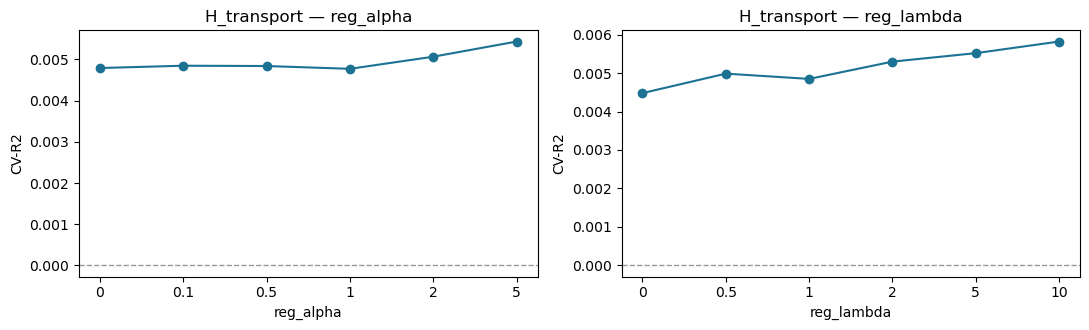

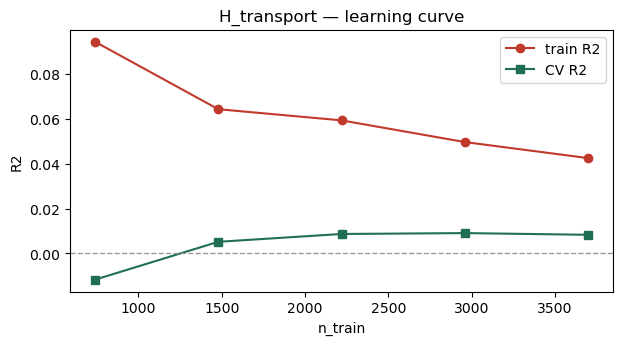

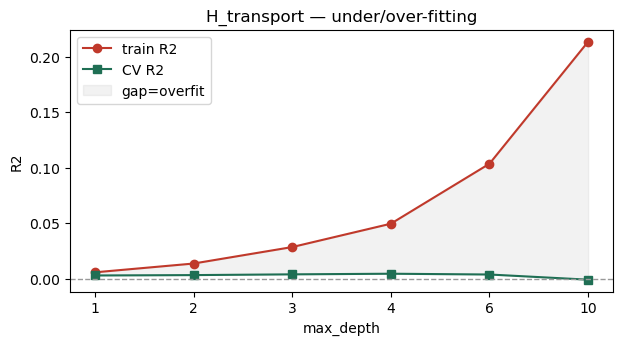

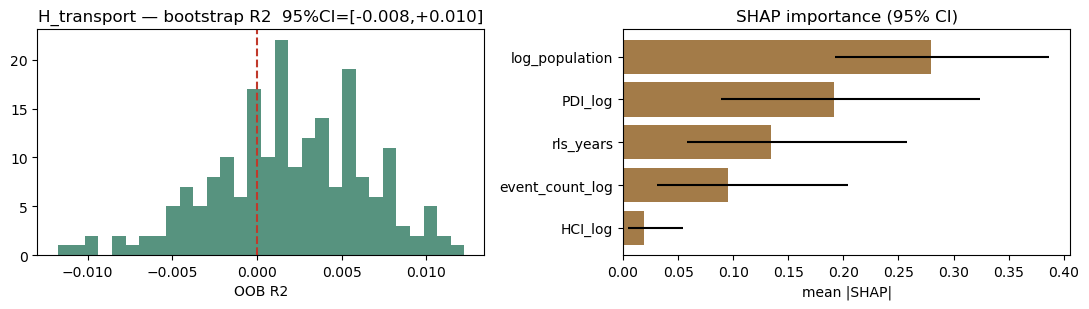


SHAP base value = 4.165 (≈ mean 4.156)
flood share = 49%  |  top = log_population


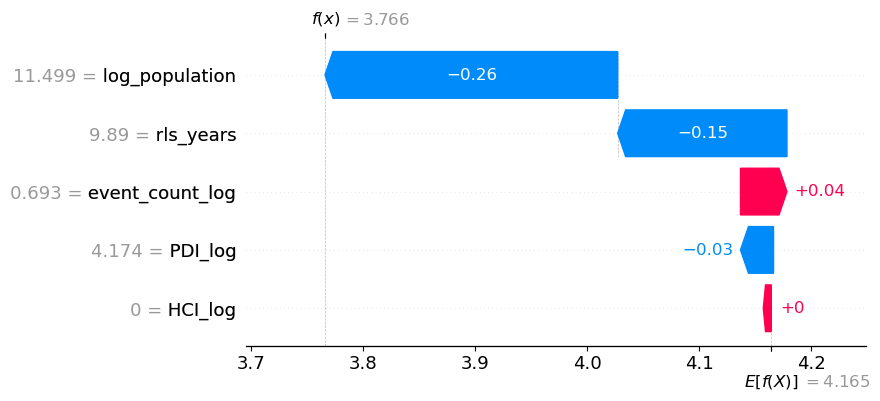

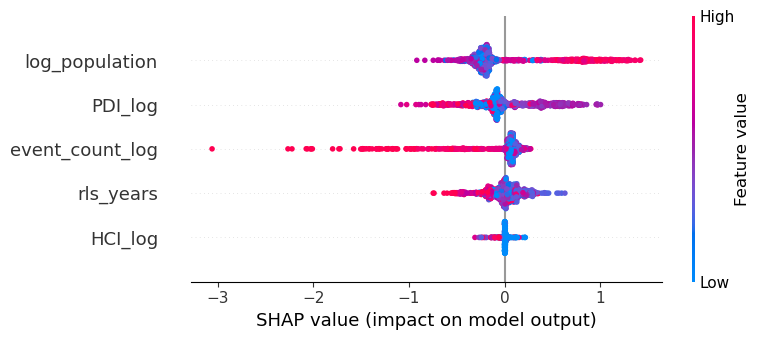

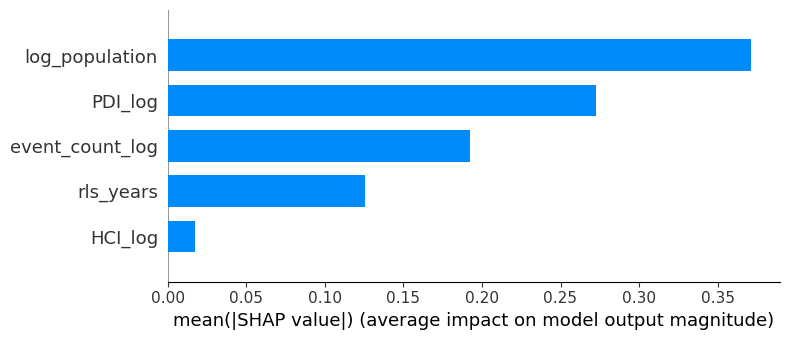

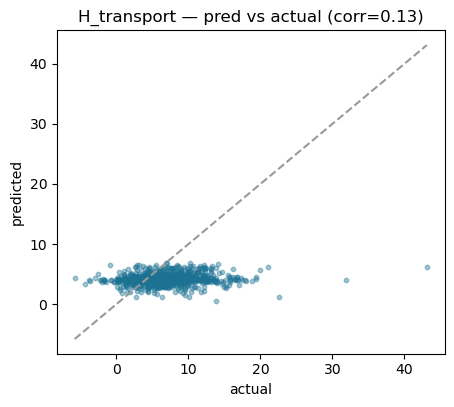

std actual=3.99  std pred=0.82 (21%)

######################################################################
#  SECTOR: I_accommodation
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 100, 'reg_alpha': 1.0, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0053

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0045    7.101    5.019
  Validation (2023)       -0.8440    5.078    4.075
  Test (2024-25)          -0.4742    4.832    3.680
  Naive baseline          -0.4332    4.764    3.633


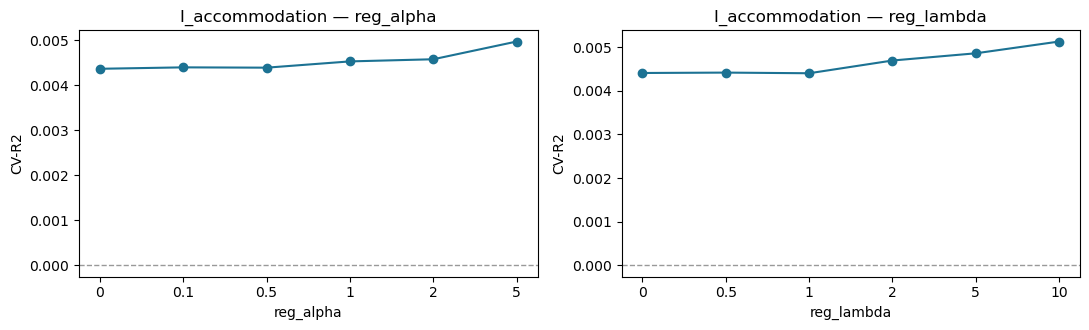

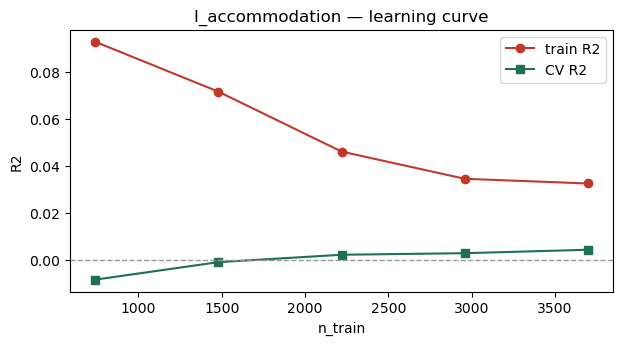

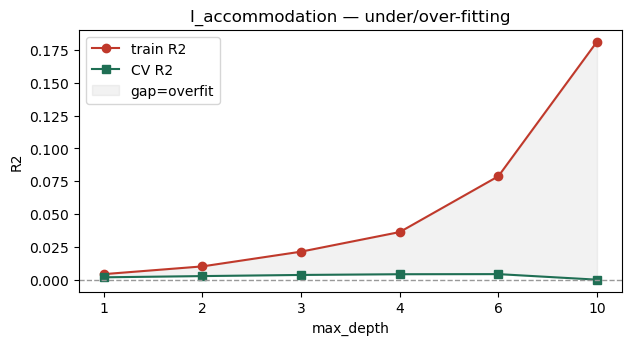

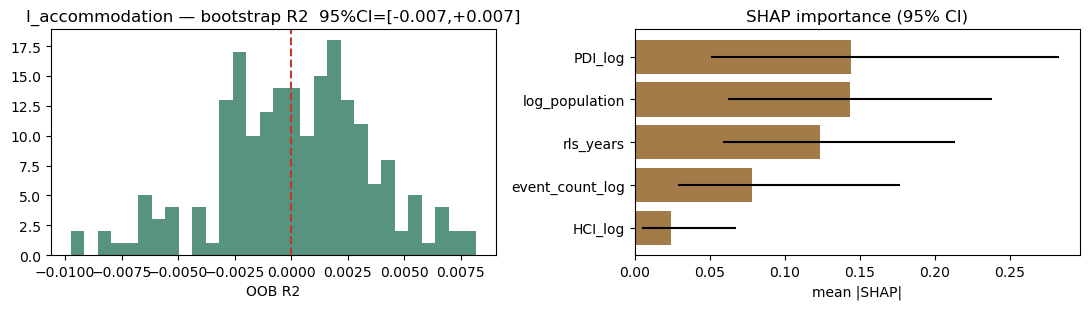


SHAP base value = 4.880 (≈ mean 4.876)
flood share = 61%  |  top = event_count_log


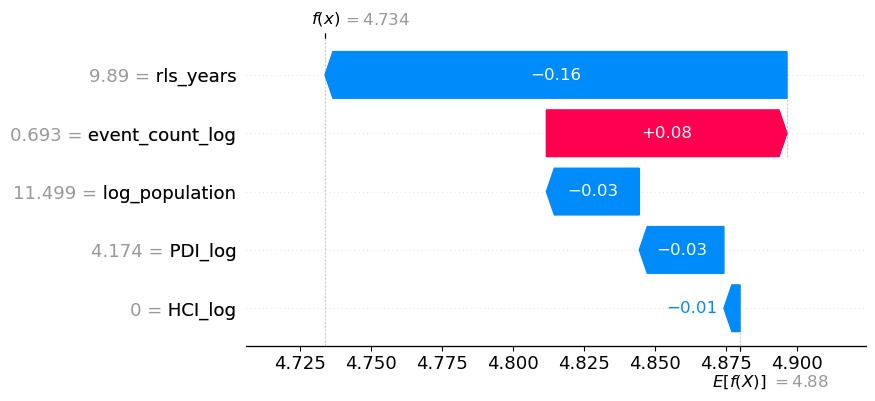

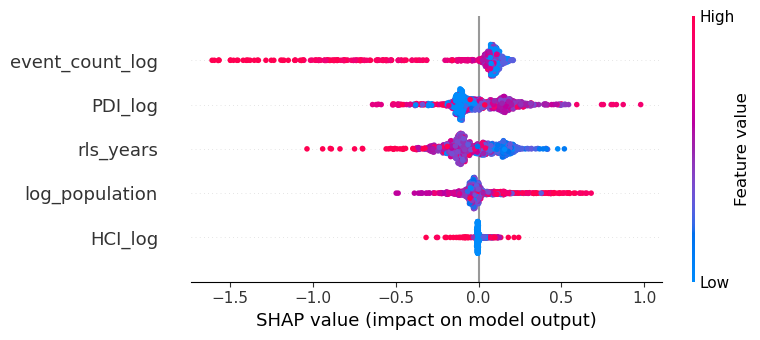

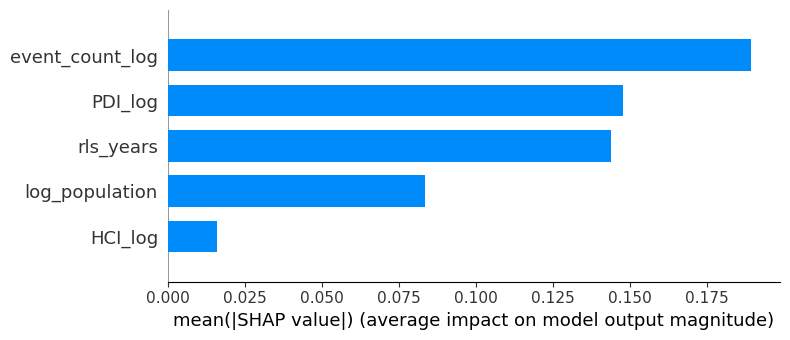

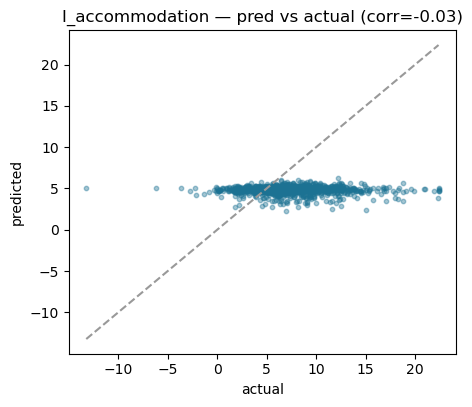

std actual=3.98  std pred=0.48 (12%)

######################################################################
#  SECTOR: J_infocomm
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0570

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0537    3.427    2.560
  Validation (2023)       -0.1172    2.950    2.249
  Test (2024-25)          -0.2450    2.976    2.415
  Naive baseline          -0.3656    3.117    2.525


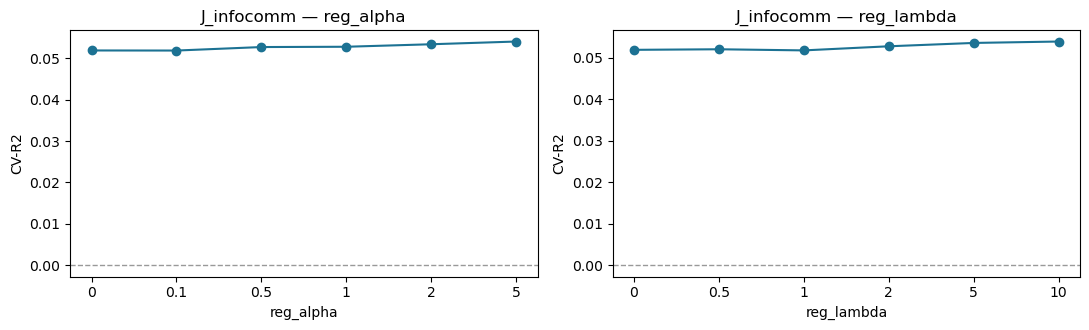

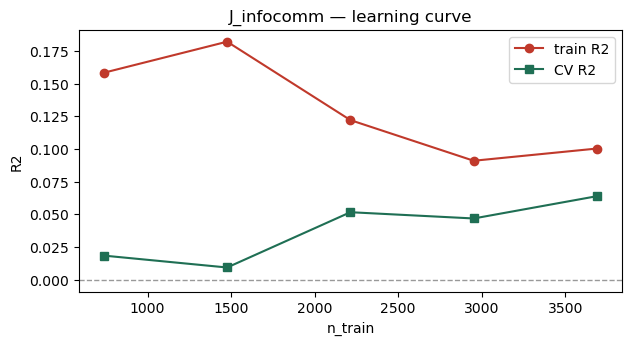

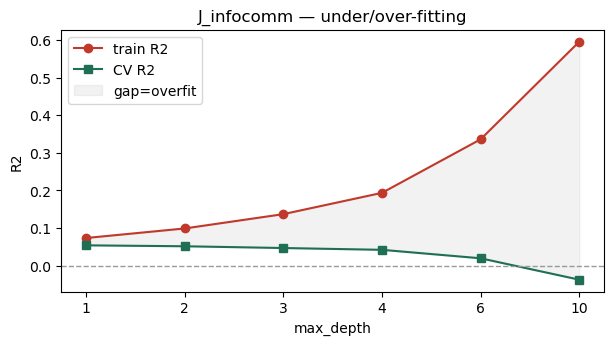

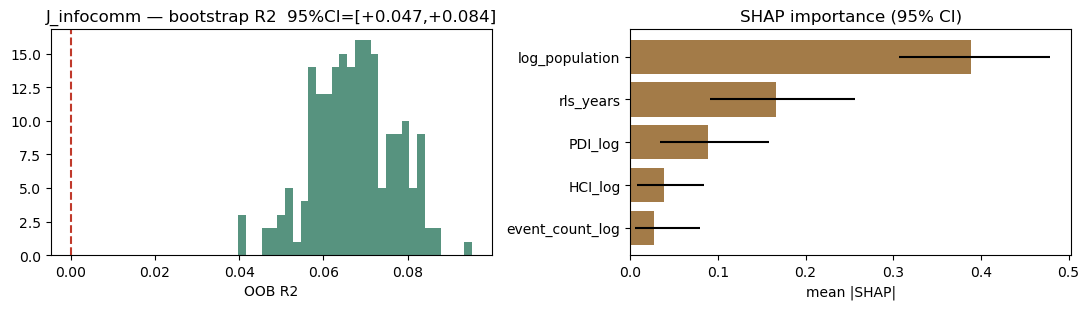


SHAP base value = 7.481 (≈ mean 7.489)
flood share = 16%  |  top = log_population


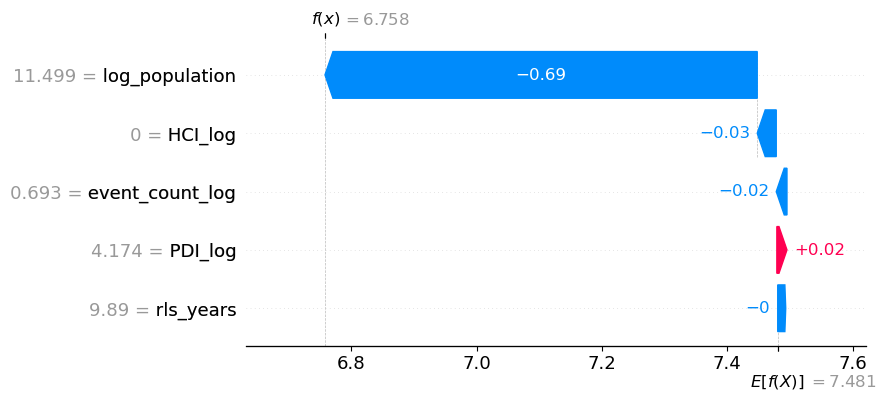

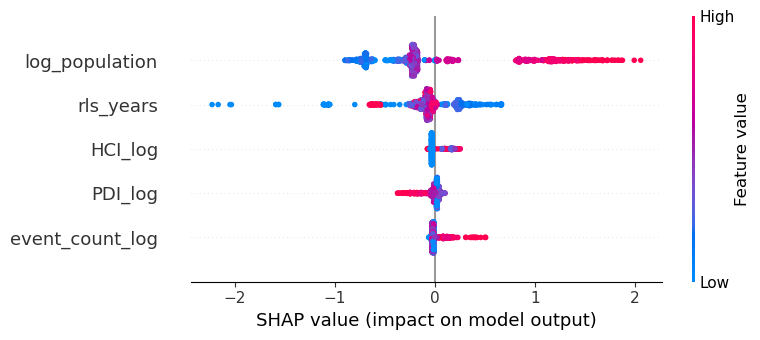

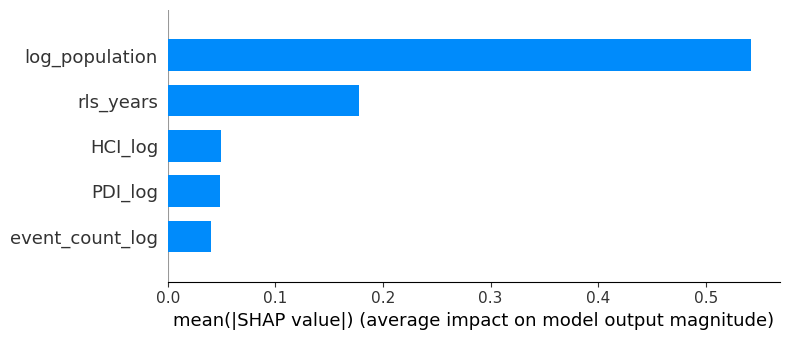

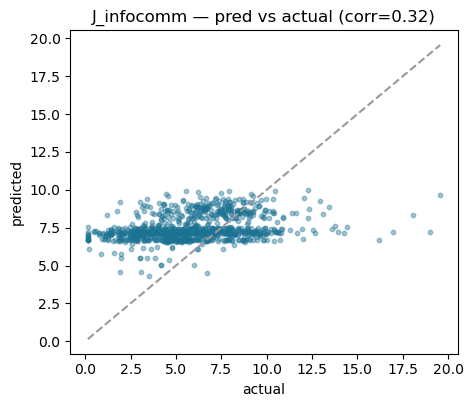

std actual=2.67  std pred=0.81 (31%)

######################################################################
#  SECTOR: K_finance
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0207

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0215    3.549    2.665
  Validation (2023)       +0.0091    4.629    3.361
  Test (2024-25)          -0.1204    4.125    2.868
  Naive baseline          -0.1074    4.101    2.811


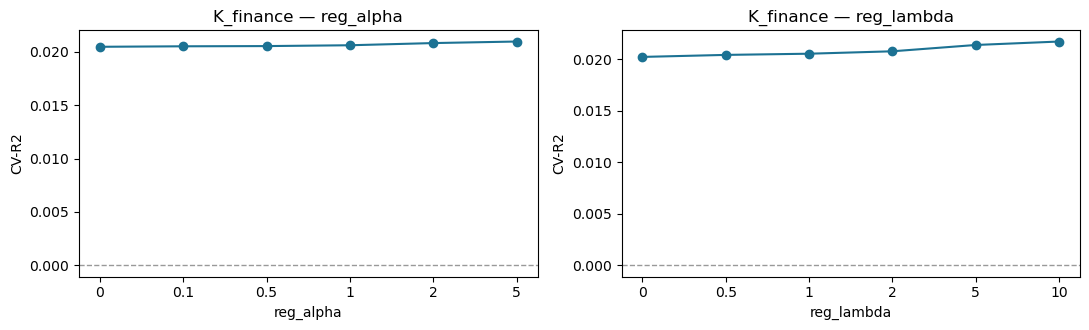

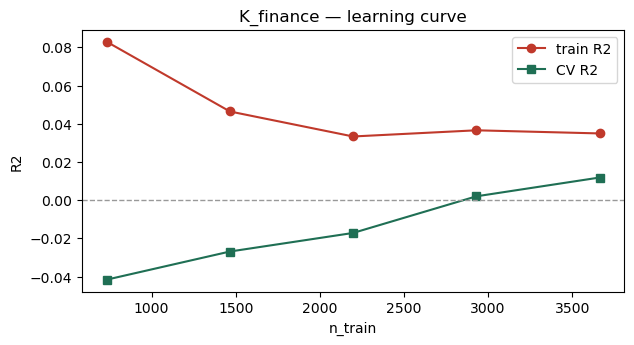

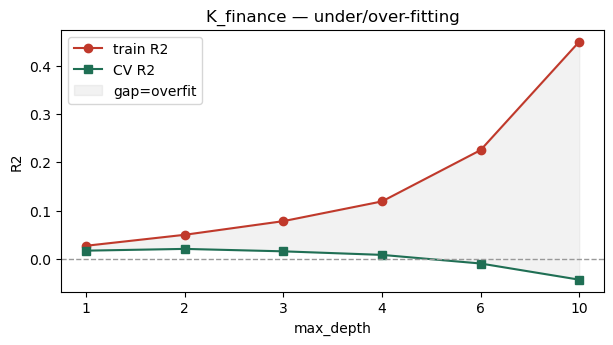

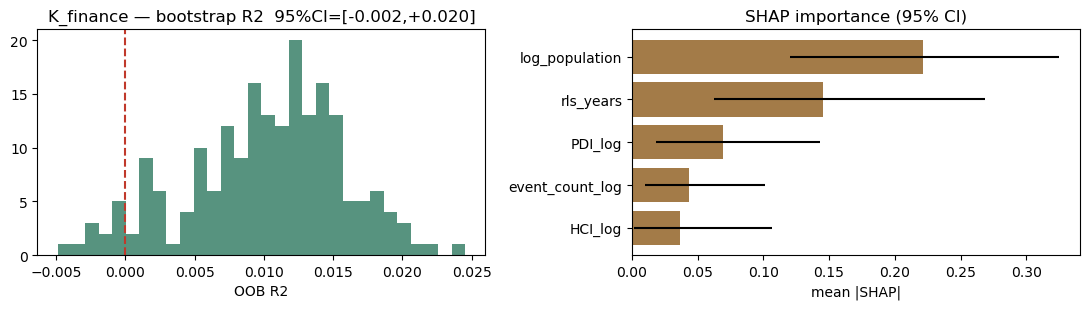


SHAP base value = 3.546 (≈ mean 3.546)
flood share = 19%  |  top = log_population


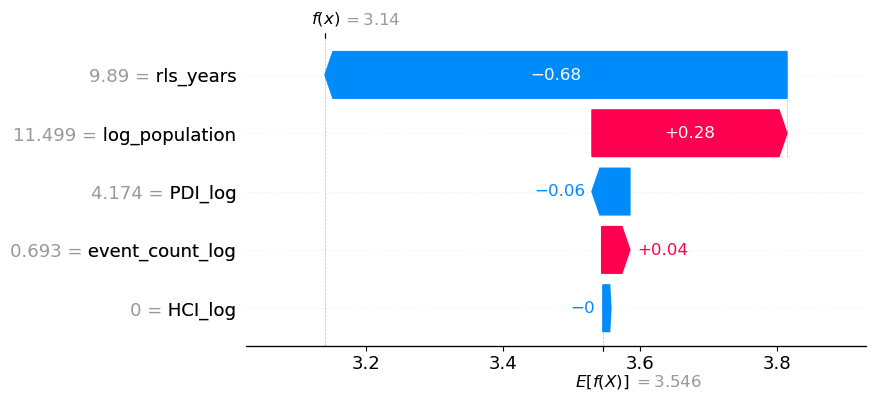

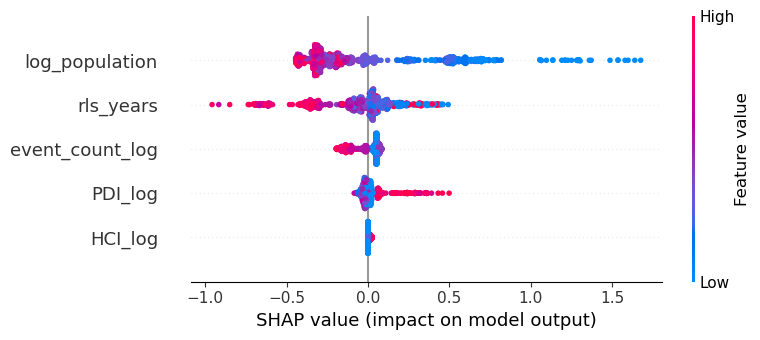

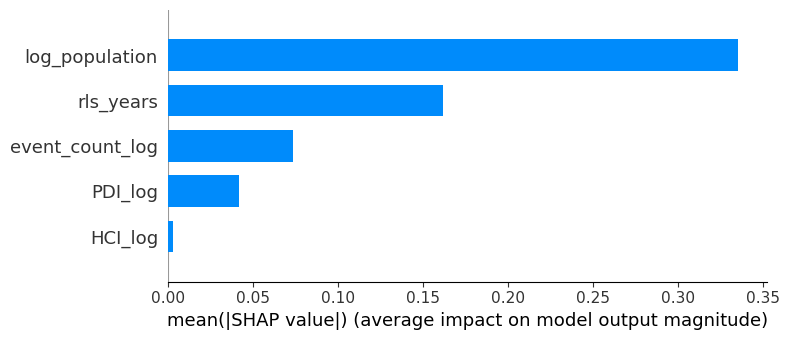

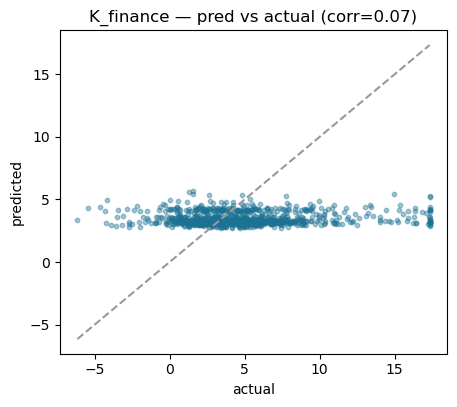

std actual=3.90  std pred=0.49 (13%)

######################################################################
#  SECTOR: L_realestate
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 100, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0495

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0490    2.707    2.189
  Validation (2023)       -0.0424    2.551    1.965
  Test (2024-25)          -0.2367    2.445    1.862
  Naive baseline          -0.1515    2.359    1.778


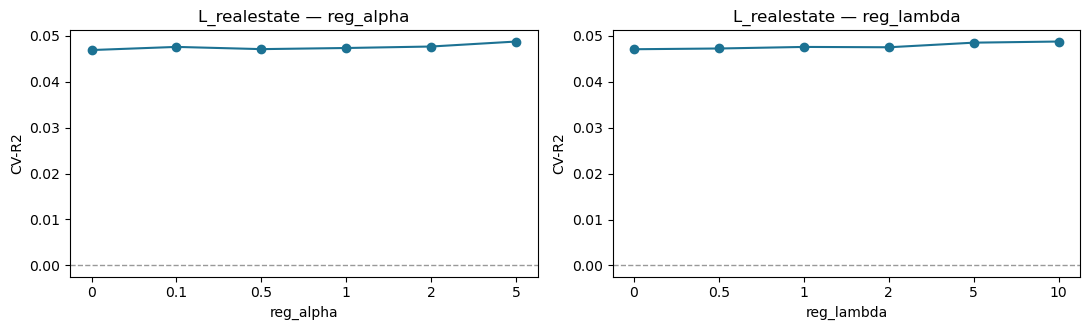

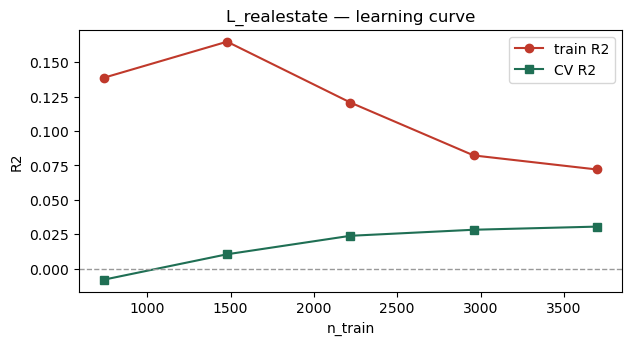

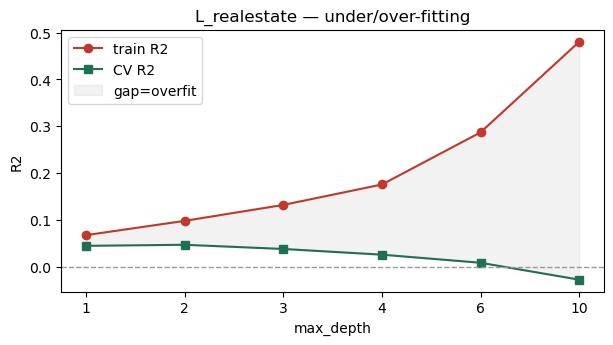

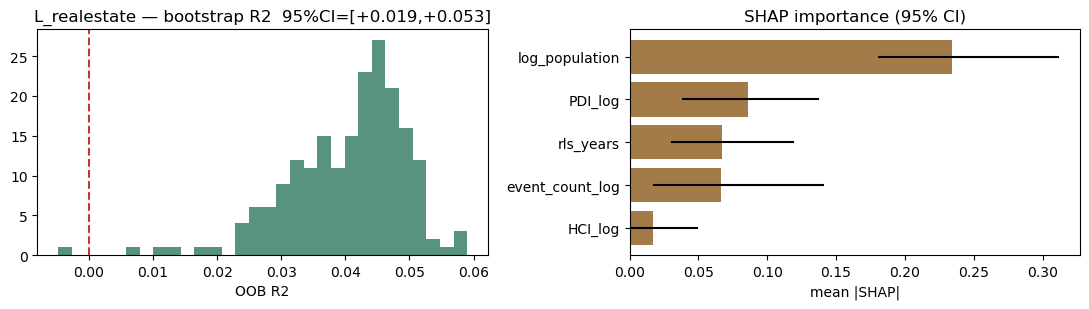


SHAP base value = 3.938 (≈ mean 3.946)
flood share = 33%  |  top = log_population


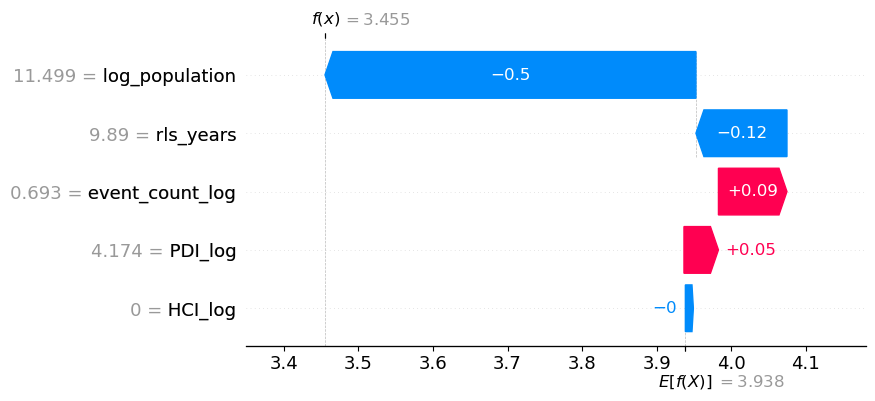

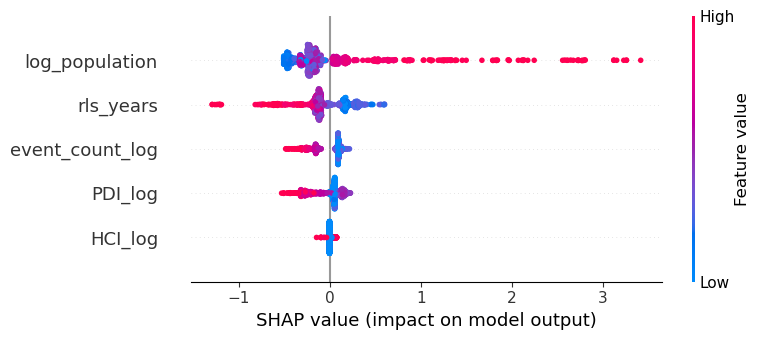

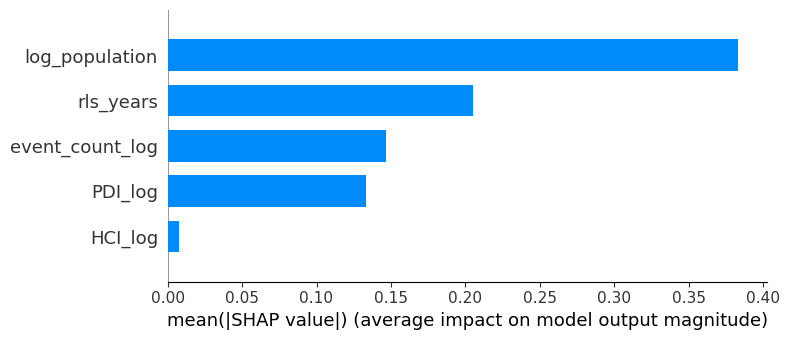

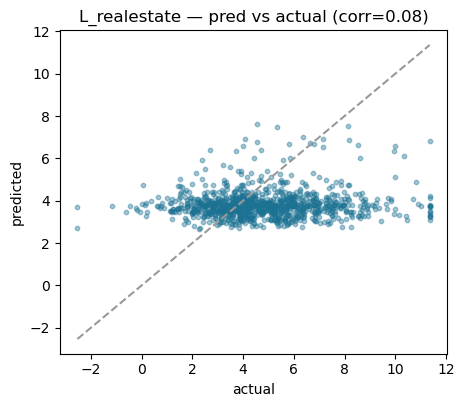

std actual=2.20  std pred=0.66 (30%)

######################################################################
#  SECTOR: MN_business
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 0, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0199

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0196    5.240    3.820
  Validation (2023)       -0.4349    4.147    3.338
  Test (2024-25)          -0.5333    3.704    3.004
  Naive baseline          -0.5010    3.665    2.991


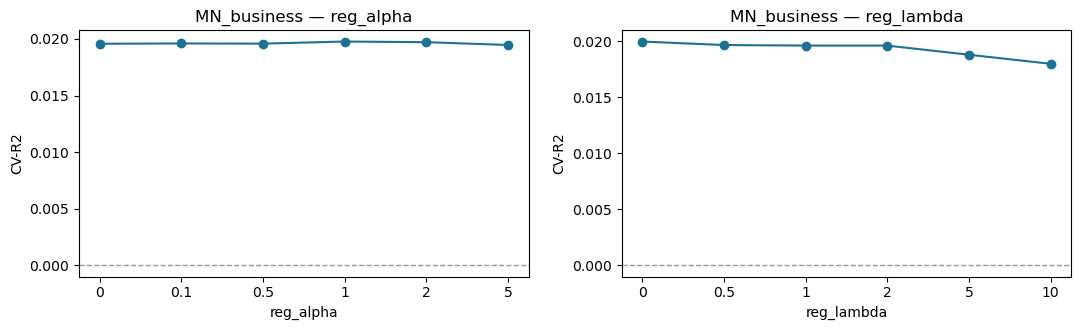

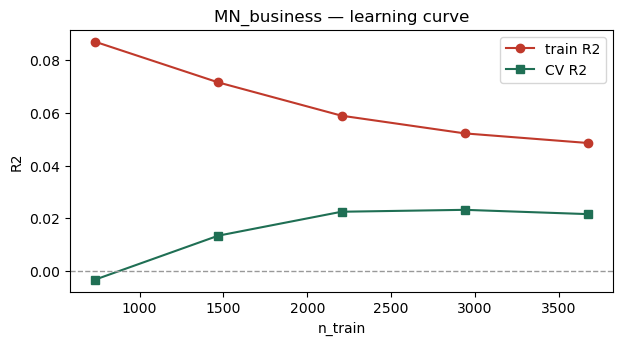

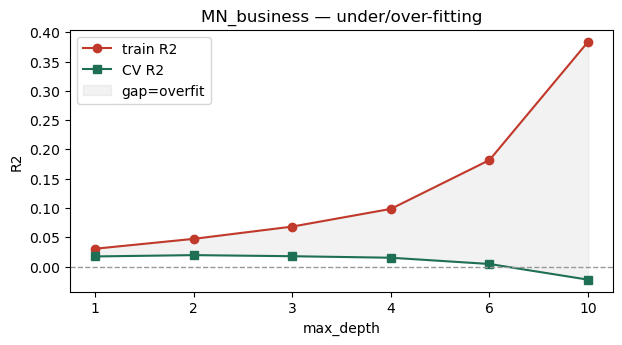

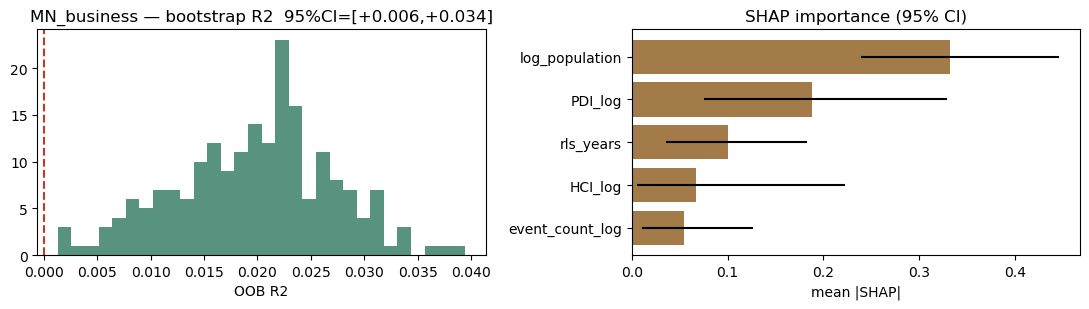


SHAP base value = 3.497 (≈ mean 3.494)
flood share = 59%  |  top = log_population


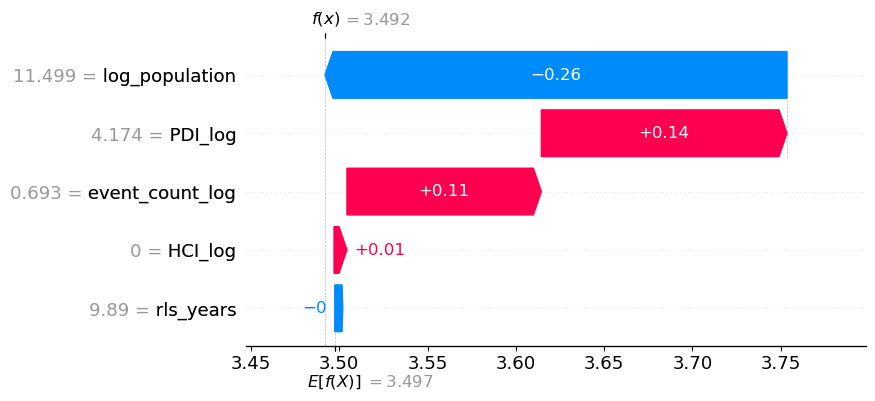

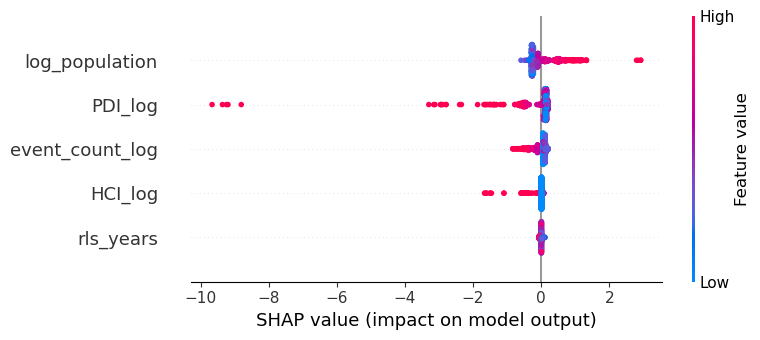

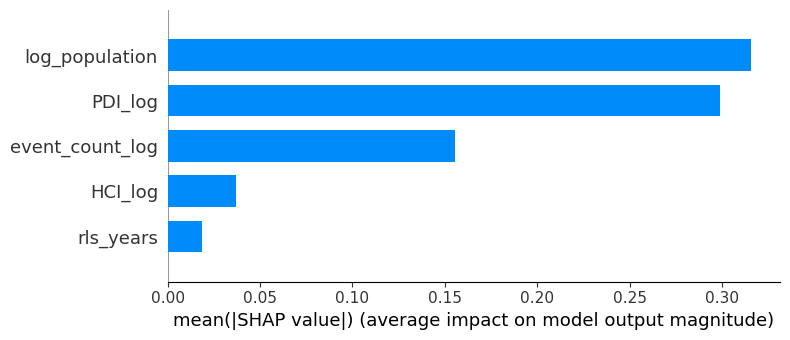

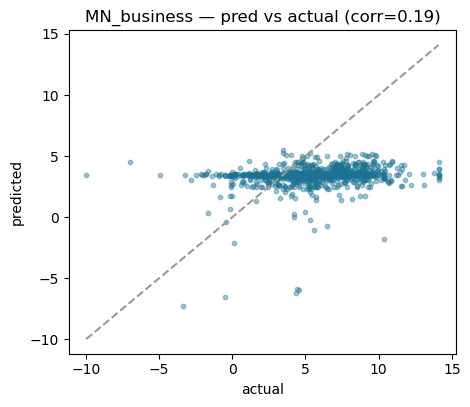

std actual=2.99  std pred=0.96 (32%)

######################################################################
#  SECTOR: O_government
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 500, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0634

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0638    3.381    2.712
  Validation (2023)       -0.0420    2.835    2.208
  Test (2024-25)          -0.4670    4.925    3.892
  Naive baseline          -0.3641    4.749    3.753


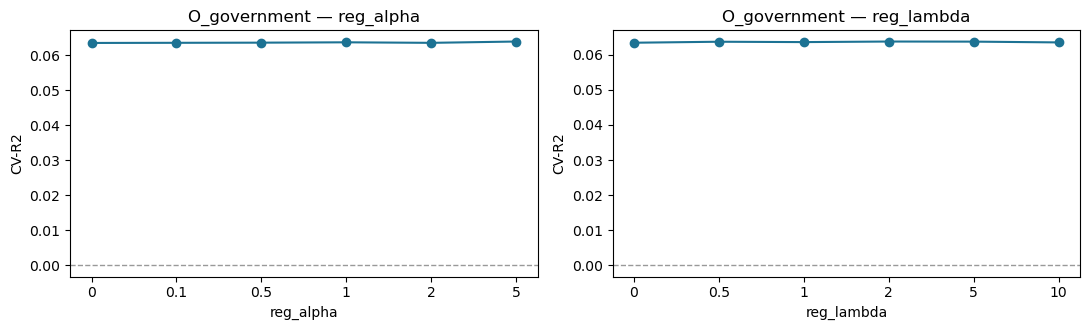

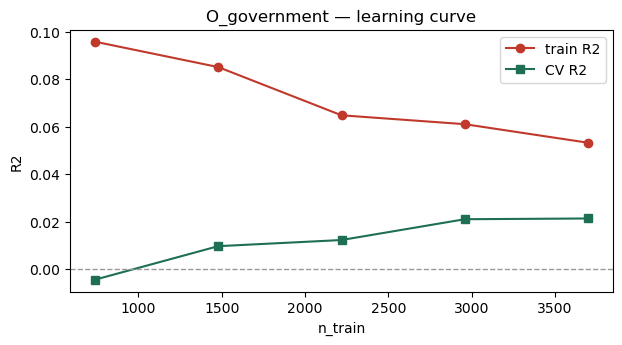

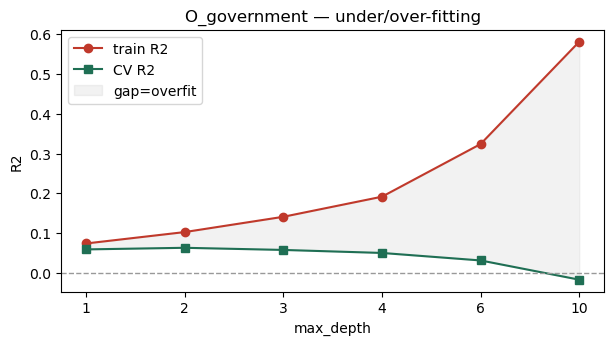

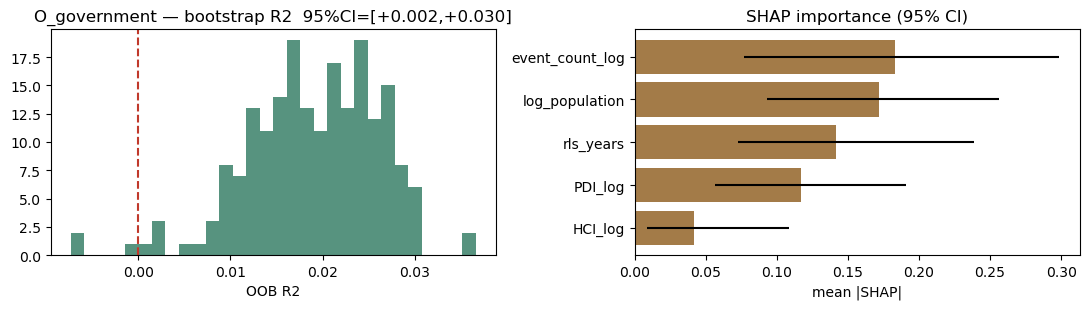


SHAP base value = 2.709 (≈ mean 2.709)
flood share = 42%  |  top = event_count_log


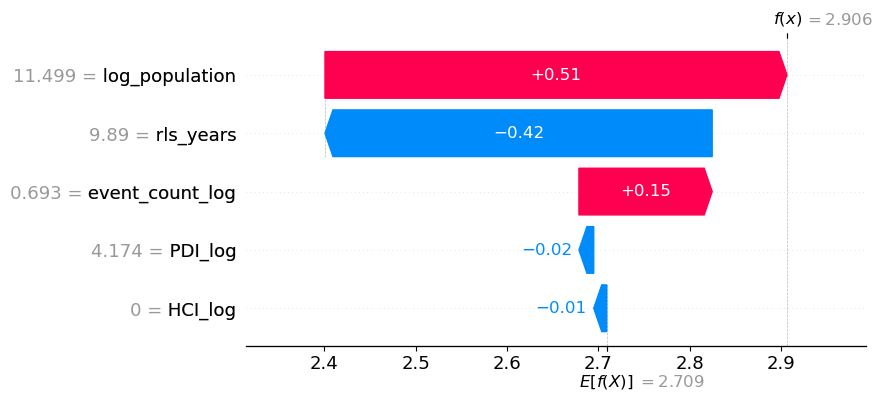

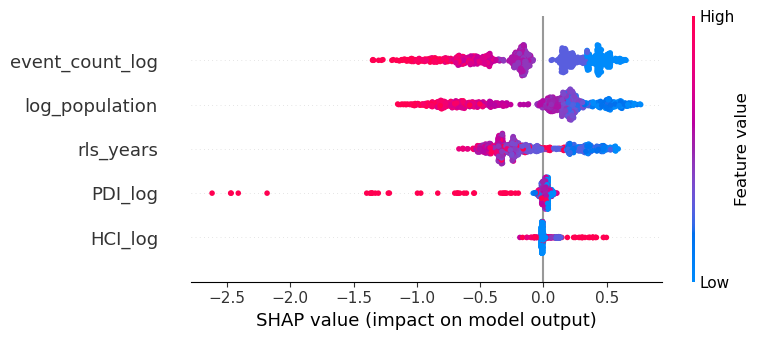

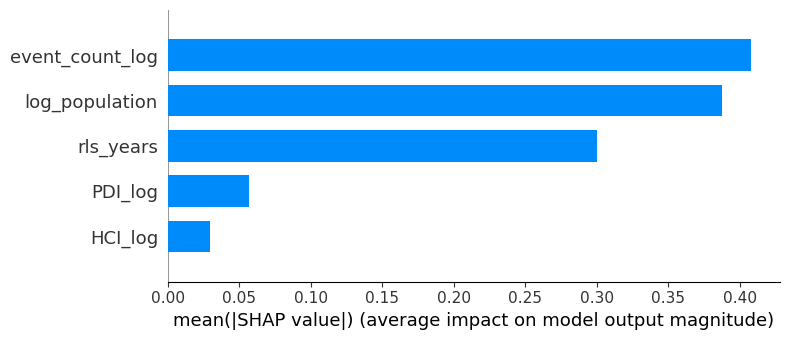

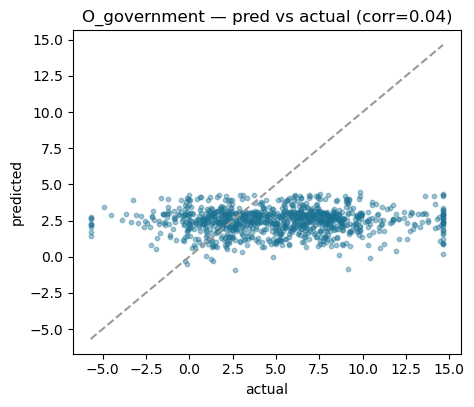

std actual=4.07  std pred=0.85 (21%)

######################################################################
#  SECTOR: P_education
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0118

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0112    2.916    2.394
  Validation (2023)       -0.0028    2.288    1.797
  Test (2024-25)          -0.0918    2.637    2.131
  Naive baseline          -0.0563    2.593    2.106


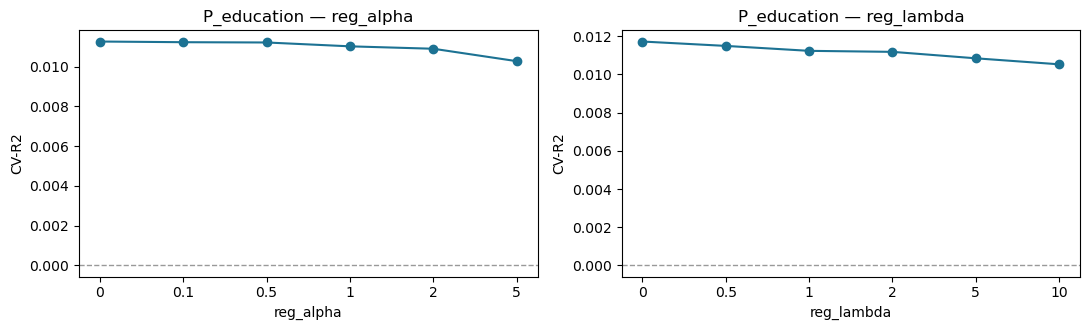

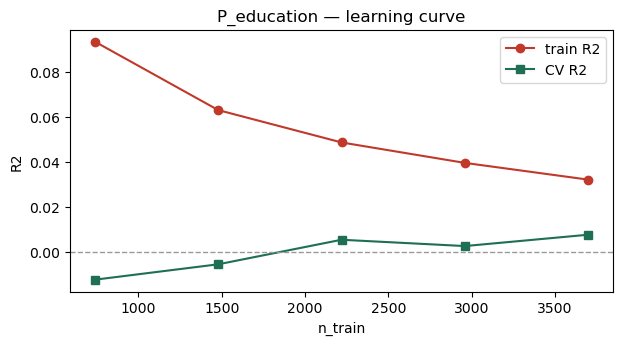

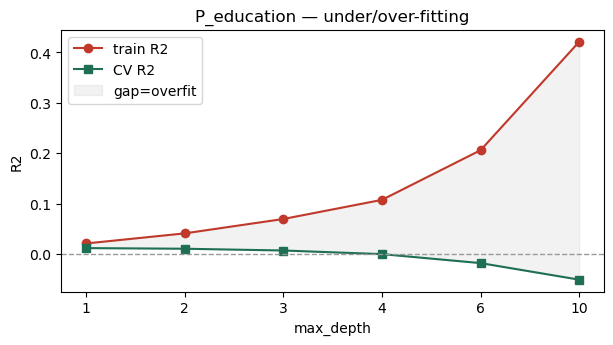

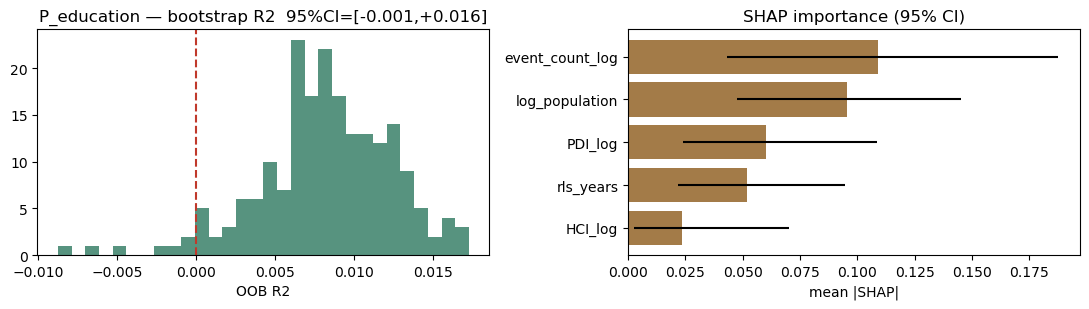


SHAP base value = 4.253 (≈ mean 4.250)
flood share = 71%  |  top = event_count_log


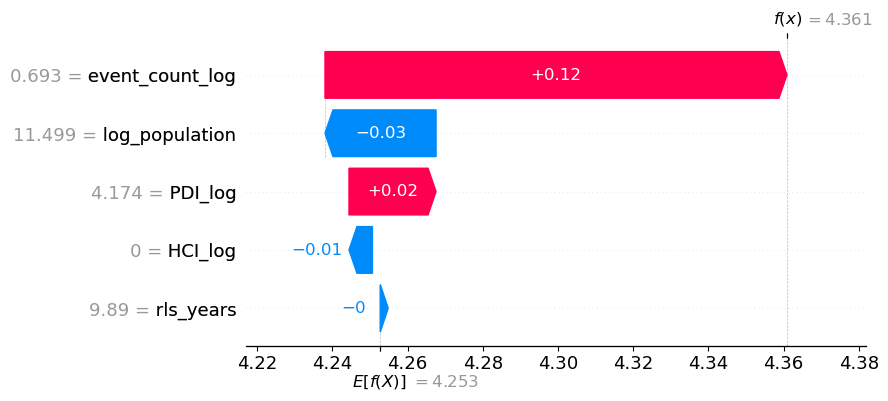

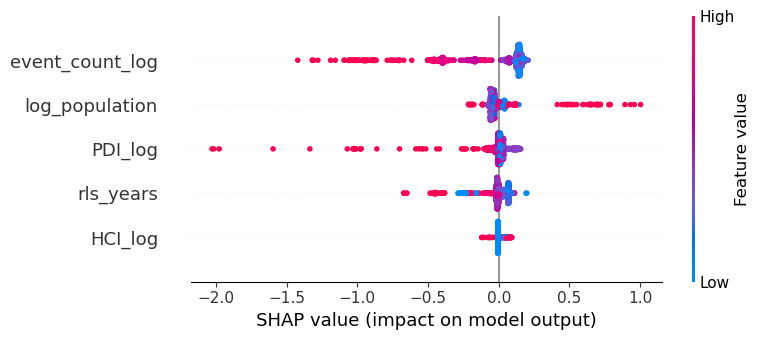

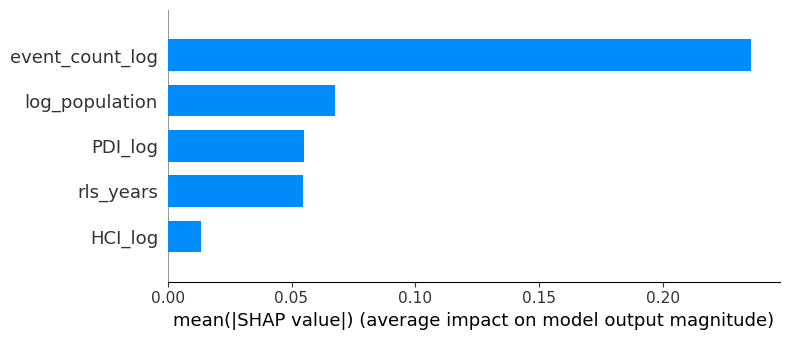

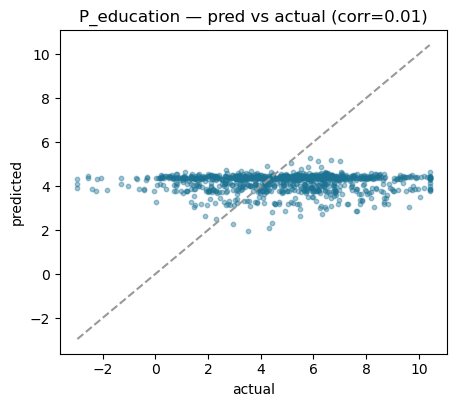

std actual=2.52  std pred=0.40 (16%)

######################################################################
#  SECTOR: Q_health
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 100, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0034

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0033    3.462    2.569
  Validation (2023)       -0.0969    3.779    2.804
  Test (2024-25)          -0.0806    2.867    2.193
  Naive baseline          -0.0900    2.880    2.196


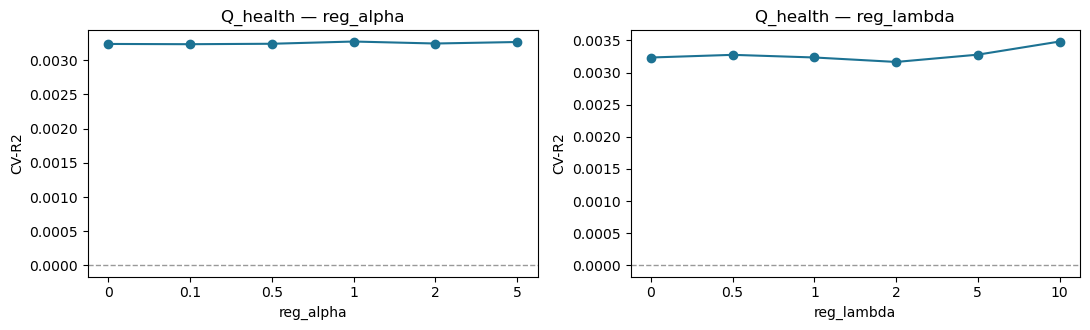

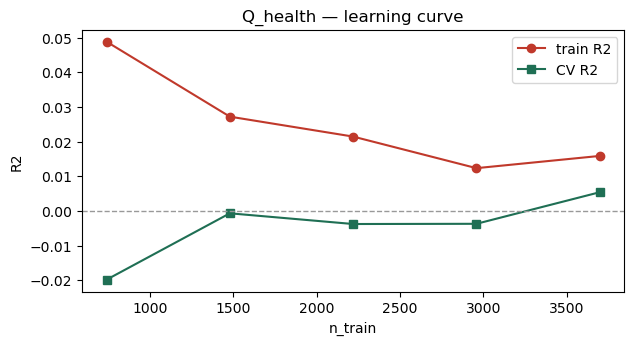

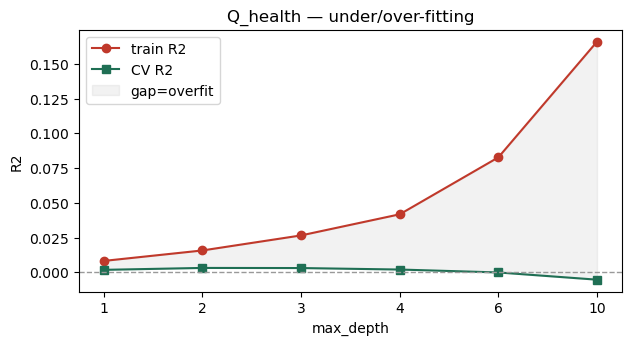

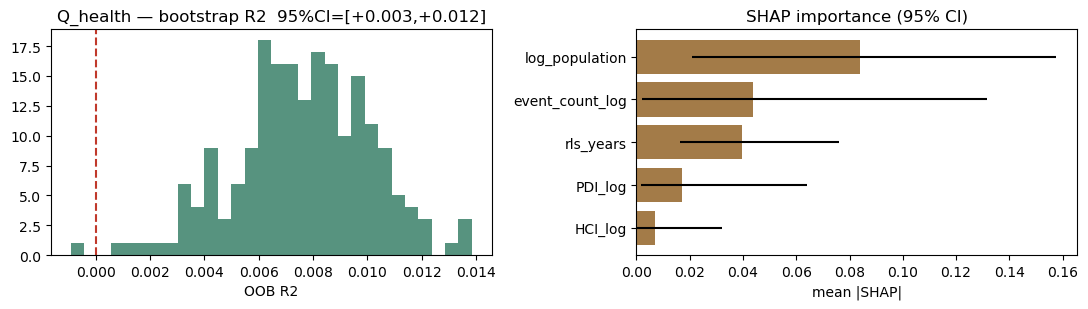


SHAP base value = 6.250 (≈ mean 6.249)
flood share = 41%  |  top = rls_years


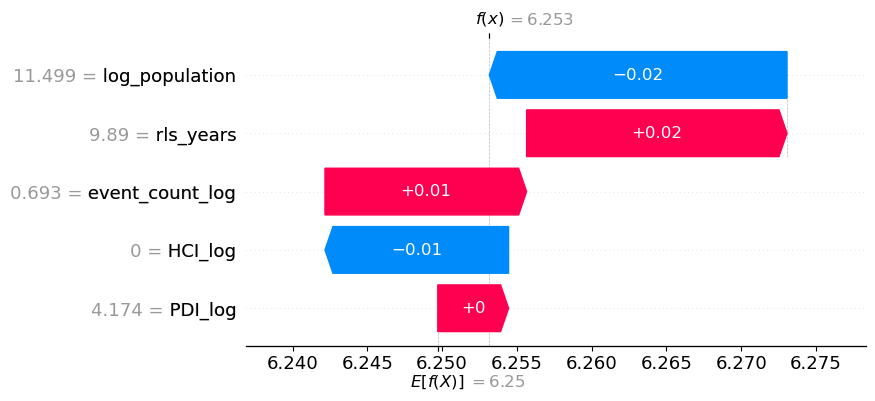

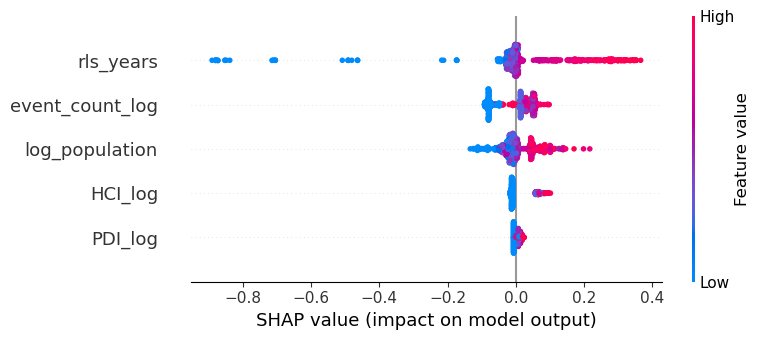

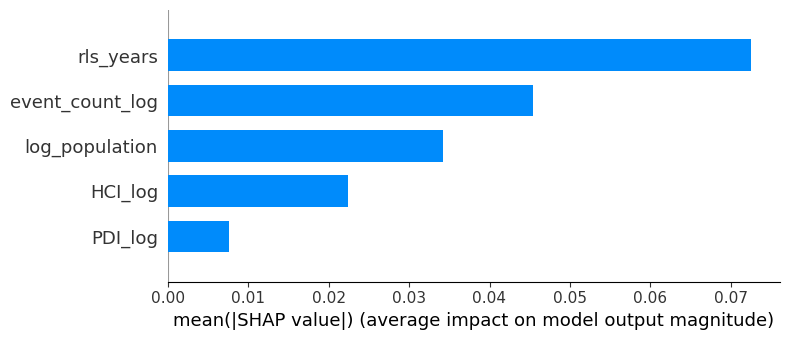

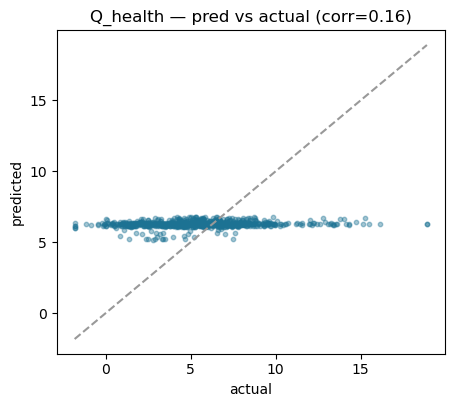

std actual=2.76  std pred=0.20 (7%)

######################################################################
#  SECTOR: RSTU_other
######################################################################

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 1.0, 'subsample': 0.8}
Best grouped-CV R2 (train): +0.0095

PERFORMANCE ACROSS THE THREE STAGES
  Stage                        R2     RMSE      MAE
  Train (CV)              +0.0091    5.825    4.204
  Validation (2023)       -0.6103    4.617    3.543
  Test (2024-25)          -0.4251    3.997    3.107
  Naive baseline          -0.4253    3.997    3.108


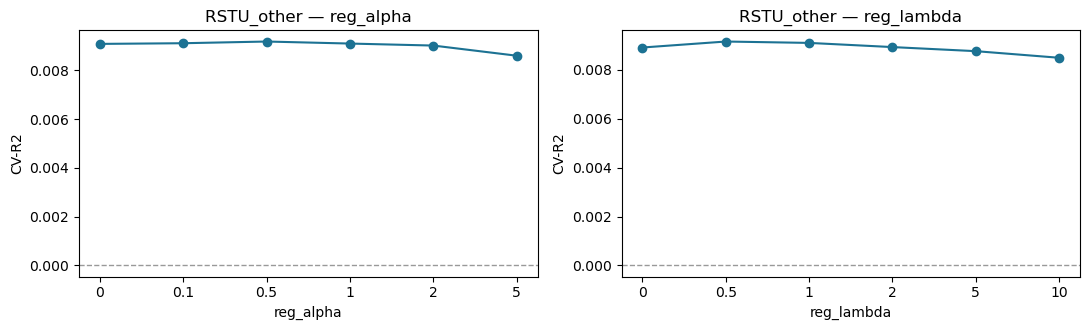

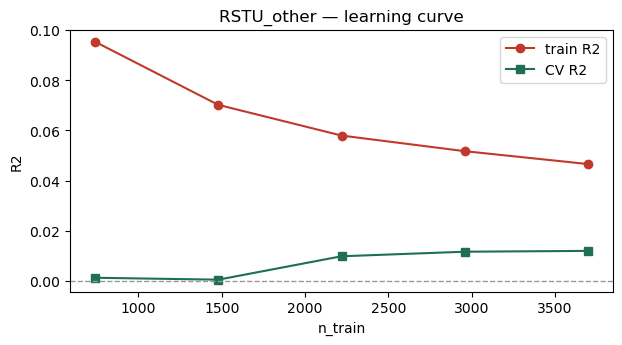

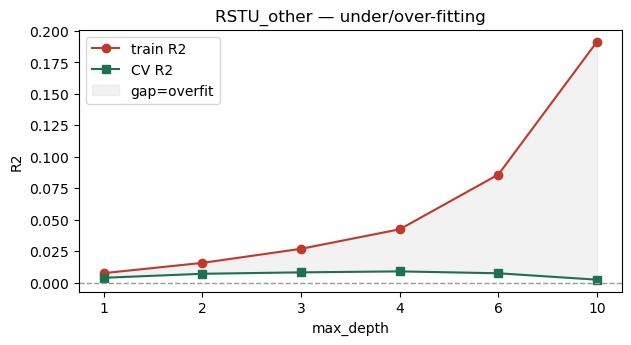

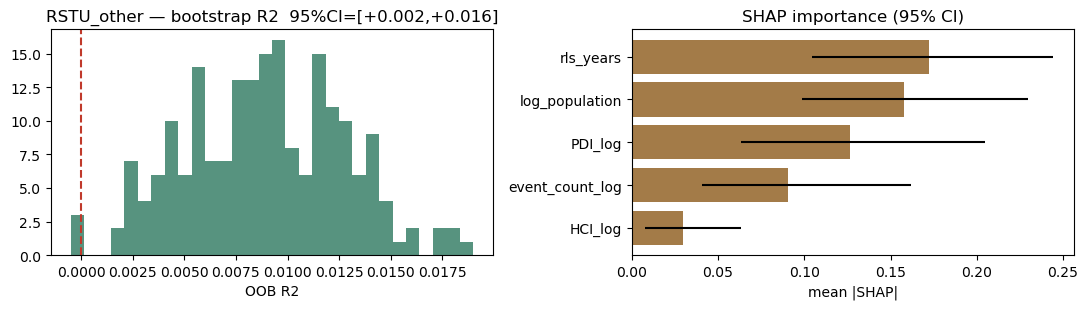


SHAP base value = 4.391 (≈ mean 4.387)
flood share = 60%  |  top = event_count_log


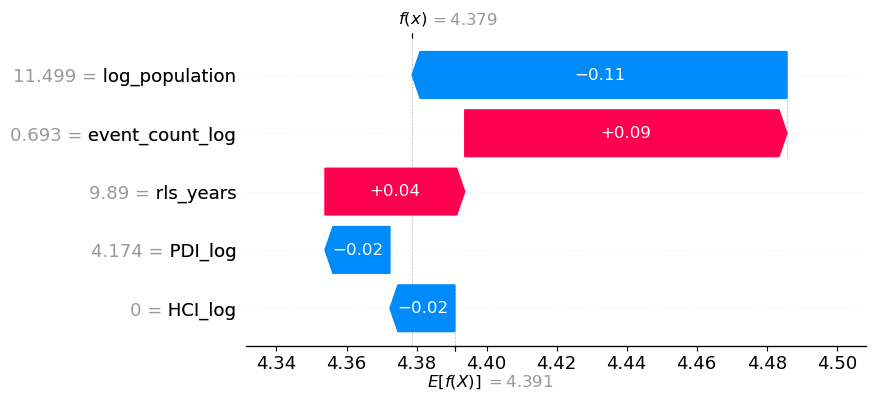

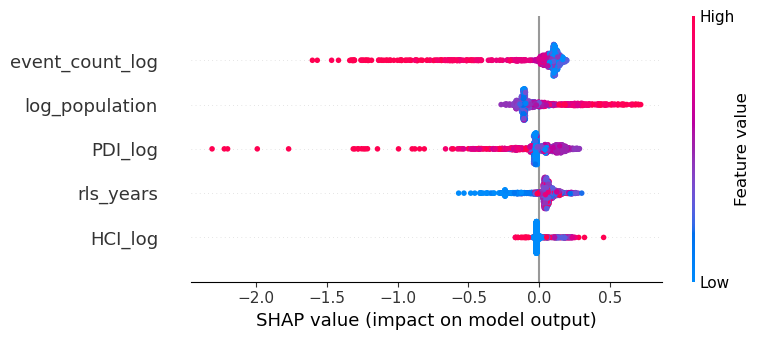

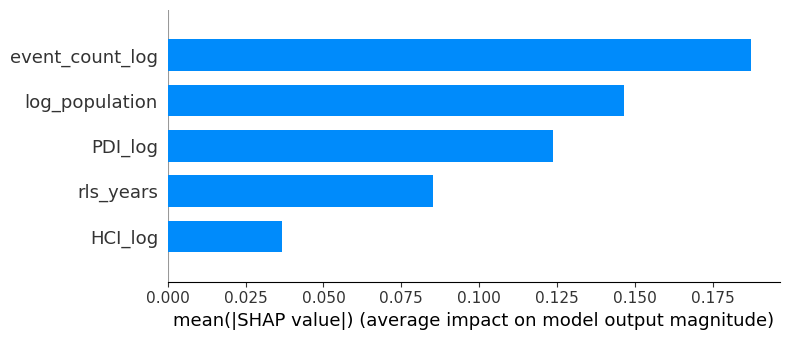

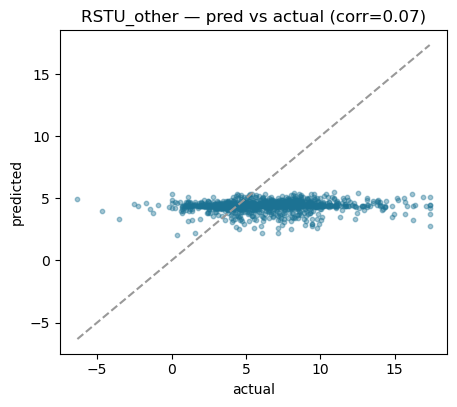

std actual=3.35  std pred=0.46 (14%)

Done.


,sector,best_cv_r2,cv_r2,cv_rmse,cv_mae,test_r2,test_rmse,test_mae,naive_r2,flood_share,top_feature,shap_event,shap_hci,shap_pdi,shap_pop,shap_rls,boot_ci_low,boot_ci_high
0,A_agriculture,0.063432,0.062255,2.376245,1.867704,-0.079120,2.910147,2.218125,-0.043273,27.829751,log_population,0.178278,0.004019,0.034663,0.372025,0.190613,0.030289,0.061147
1,B_mining,0.021729,0.020840,6.163607,4.168984,0.022569,5.814891,3.710911,-0.000214,23.075512,log_population,0.148199,0.008507,0.053328,0.356787,0.343381,0.020902,0.037438
2,C_manufacturing,0.016482,0.016332,4.784064,3.234736,-0.138128,5.325977,3.310361,-0.126649,32.870030,rls_years,0.130453,0.013223,0.138738,0.260385,0.316386,0.002084,0.020375
3,D_electricity,0.036363,0.036638,4.482731,3.094366,0.030630,4.705330,3.231579,-0.011086,22.437149,log_population,0.164944,0.020410,0.028917,0.398057,0.342652,0.021399,0.052409
4,E_water,0.018719,0.018581,3.270169,2.487027,-0.157338,3.597958,2.843645,-0.155785,13.126509,rls_years,0.012644,0.008751,0.053839,0.178549,0.319366,0.010314,0.031063
5,F_construction,0.016791,0.016716,4.918232,3.752348,-0.013319,4.257404,3.152118,-0.007691,40.600687,rls_years,0.353040,0.010344,0.033412,0.166875,0.413643,0.004170,0.024475
6,G_trade,0.015104,0.014958,4.269555,3.141295,-0.309040,2.965140,2.198762,-0.244228,55.452073,event_count_log,0.326161,0.006666,0.083736,0.161817,0.172833,-0.001348,0.017066
7,H_transport,0.005654,0.005518,9.873830,6.024580,-0.390307,4.702720,3.446663,-0.401931,49.266204,log_population,0.192452,0.017106,0.272721,0.371096,0.125550,-0.007931,0.010090
8,I_accommodation,0.005288,0.004533,7.101239,5.018780,-0.474173,4.832102,3.680119,-0.433197,60.832834,event_count_log,0.189342,0.016114,0.147940,0.083539,0.143995,-0.007115,0.006766
9,J_infocomm,0.056969,0.053695,3.426586,2.559933,-0.244985,2.976302,2.414541,-0.365600,16.163048,log_population,0.040461,0.049492,0.048835,0.541947,0.177941,0.047466,0.084117


In [6]:
# ═════════════════════════════════════════════════════════════
# STEP 2 — Run the pipeline (per `SECTORS_TO_RUN`)
# ═════════════════════════════════════════════════════════════
xgb_results = []
for s in SECTORS_TO_RUN:
    xgb_results.append(run_full_sector(s))
xgb_sec_df = pd.DataFrame(xgb_results)
print("\nDone.")
xgb_sec_df

## STEP 3 — FE vs XGBoost comparison (FE read from `fit_9b.json`)

FE results come from nb9b. Make sure `fit_9b.json` is in the working directory.

In [8]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — FE vs XGBoost comparison (FE read from `fit_9b.json`)
# ═════════════════════════════════════════════════════════════
# Load FE results exported by nb9b
with open("fit_9b.json") as f:
    fe9b = json.load(f)
fe_lookup = {}
for sec, v in fe9b["sectors"].items():
    sig = []
    for dim in ["event", "HCI", "PDI"]:
        dd = v["dims"].get(dim, {})
        if dd.get("sig_any"):
            sig.append(f"{dim}({dd['beta']:+.2f})")
    fe_lookup[sec] = dict(
        fe_sig=", ".join(sig) if sig else "none sig",
        block_p=v.get("flood_block_pval", np.nan),
        model_sig=v.get("model_significant", False),
    )
# ── Build a rich comparison table ──
rows = []
for _, r in xgb_sec_df.iterrows():
    fe = fe_lookup.get(r.sector, {})
    # flood vs control SHAP share (control = 100 - flood)
    flood = r.get("flood_share", np.nan)
    ctrl  = 100 - flood if pd.notna(flood) else np.nan
    # is the small signal (if any) coming from flood or controls?
    top_is_flood = str(r.get("top_feature", "")) in ["event_count_log", "HCI_log", "PDI_log"]
    signal_src = "flood" if top_is_flood else "control"
    # honest verdict combining CV and test
    cv, te = r.cv_r2, r.test_r2
    if cv > 0.02 and te > 0:
        verdict = "weak signal"          # both slightly positive
    elif cv > 0.02 and te <= 0:
        verdict = "CV-only (fails test)" # looked ok in CV, collapses on test
    else:
        verdict = "no signal"
    rows.append(dict(
        sector=r.sector,
        # ---- FE (inference) ----
        FE_sig=fe.get("fe_sig", "?"),
        FE_block_p=round(fe.get("block_p", np.nan), 3),
        # ---- XGBoost (prediction) ----
        XGB_CV_R2=round(cv, 4),
        XGB_test_R2=round(te, 4),
        boot_CI=f"[{r.get('boot_ci_low', np.nan):+.3f},{r.get('boot_ci_high', np.nan):+.3f}]",
        # ---- SHAP decomposition ----
        flood_pct=f"{flood:.0f}%" if pd.notna(flood) else "?",
        ctrl_pct=f"{ctrl:.0f}%" if pd.notna(ctrl) else "?",
        top_feat=r.get("top_feature", "?"),
        signal_from=signal_src,
        # ---- combined verdict ----
        verdict=verdict,
    ))
cmp_df = pd.DataFrame(rows)
# sort: FE-significant first, then by CV-R2
cmp_df["_fe_any"] = cmp_df.FE_sig != "none sig"
cmp_df = cmp_df.sort_values(["_fe_any", "XGB_CV_R2"], ascending=[False, False]).drop(columns="_fe_any").reset_index(drop=True)
pd.set_option("display.max_columns", None, "display.width", 200)
print("FE (nb9b, inference) vs XGBoost (prediction) — full comparison")
print("=" * 120)
print(cmp_df.to_string(index=False))
print("=" * 120)
# ── Automated reading ──
n_fe_sig   = (cmp_df.FE_sig != "none sig").sum()
n_xgb_weak = (cmp_df.verdict == "weak signal").sum()
n_both     = ((cmp_df.FE_sig != "none sig") & (cmp_df.verdict == "weak signal")).sum()
n_flood_src = (cmp_df.signal_from == "flood").sum()
print("\n── Sharp reading ──")
print(f"• FE finds ≥1 significant flood dimension in {n_fe_sig}/17 sectors (inference).")
print(f"• XGBoost shows a weak signal (CV>0.02 AND test>0) in only {n_xgb_weak}/17 sectors.")
print(f"• Sectors BOTH FE-significant AND XGBoost-predictive: {n_both}/17.")
print(f"• Of all sectors, the top SHAP feature is a flood dimension in {n_flood_src}/17;")
print(f"  in the rest the model leans on CONTROLS (population/schooling), so any")
print(f"  small predictive signal is NOT coming from flooding.")
print("• 'CV-only (fails test)' = looked slightly predictive in cross-validation but")
print("  R² turns negative on the untouched 2024–25 years → not a real signal.")
print("• Bottom line: no sector shows flood-driven predictive power that survives the")
print("  test set; FE-significant sectors (trade, construction…) are the")
print("  significance-≠-prediction pattern, consistent with headline growth.")
cmp_df

FE (nb9b, inference) vs XGBoost (prediction) — full comparison
         sector                   FE_sig  FE_block_p  XGB_CV_R2  XGB_test_R2         boot_CI flood_pct ctrl_pct        top_feat signal_from              verdict
       B_mining               PDI(-0.04)       0.031     0.0208       0.0226 [+0.021,+0.037]       23%      77%  log_population     control          weak signal
    MN_business event(+0.34), HCI(-0.18)       0.001     0.0196      -0.5333 [+0.006,+0.034]       59%      41%  log_population     control            no signal
 F_construction event(+0.40), HCI(-0.18)       0.000     0.0167      -0.0133 [+0.004,+0.024]       41%      59%       rls_years     control            no signal
C_manufacturing               PDI(-0.07)       0.000     0.0163      -0.1381 [+0.002,+0.020]       33%      67%       rls_years     control            no signal
        G_trade             event(+0.30)       0.000     0.0150      -0.3090 [-0.001,+0.017]       55%      45% event_count_log     

,sector,FE_sig,FE_block_p,XGB_CV_R2,XGB_test_R2,boot_CI,flood_pct,ctrl_pct,top_feat,signal_from,verdict
0,B_mining,PDI(-0.04),0.031,0.0208,0.0226,"[+0.021,+0.037]",23%,77%,log_population,control,weak signal
1,MN_business,"event(+0.34), HCI(-0.18)",0.001,0.0196,-0.5333,"[+0.006,+0.034]",59%,41%,log_population,control,no signal
2,F_construction,"event(+0.40), HCI(-0.18)",0.000,0.0167,-0.0133,"[+0.004,+0.024]",41%,59%,rls_years,control,no signal
3,C_manufacturing,PDI(-0.07),0.000,0.0163,-0.1381,"[+0.002,+0.020]",33%,67%,rls_years,control,no signal
4,G_trade,event(+0.30),0.000,0.0150,-0.3090,"[-0.001,+0.017]",55%,45%,event_count_log,flood,no signal
5,P_education,HCI(-0.13),0.001,0.0112,-0.0918,"[-0.001,+0.016]",71%,29%,event_count_log,flood,no signal
6,RSTU_other,HCI(-0.16),0.044,0.0091,-0.4251,"[+0.002,+0.016]",60%,40%,event_count_log,flood,no signal
7,I_accommodation,HCI(-0.18),0.000,0.0045,-0.4742,"[-0.007,+0.007]",61%,39%,event_count_log,flood,no signal
8,Q_health,event(+0.39),0.001,0.0033,-0.0806,"[+0.003,+0.012]",41%,59%,rls_years,control,no signal
9,O_government,none sig,0.283,0.0638,-0.4670,"[+0.002,+0.030]",42%,58%,event_count_log,flood,CV-only (fails test)
